# Tesis

## Librrerías y datos

In [1]:
#!/usr/bin/env python3
"""The first code cell of every notebook a job may run — copied byte for byte.

One question, answered once: WHERE IS THE REPOSITORY THIS NOTEBOOK RUNS
AGAINST. Every later cell reads `ROOT` and none of them asks again.

Opened by a person on their own machine, this answers it exactly the way
these notebooks always have. A notebook lives at `<repo>/<Name>/Notebooks/`,
so the repository is two directories above the working directory. Nothing was
handed over, nothing is checked, and the behaviour is unchanged.

Started by a runner on a remote worker, it does not answer it by looking
around. The runner exports the directory it cloned the pinned commit into and
the commit it pinned; this cell reads both, and PROVES the checkout is at that
commit before returning it.

Guessing is the whole reason this cell exists. Under the runner the kernel's
working directory is the runner's own and the clone sits one level inside it,
so two directories up is two levels ABOVE the working directory — a directory
that EXISTS on any worker. The path resolves, the insert succeeds, and the run
dies later with a missing module naming a package, never with the wrong root.
The one fact worth having is the one the failure never mentions.

Three refusals, and each one is a refusal rather than a fallback because this
is the path that spends metered quota:

- **Half a handoff** — one variable present and the other missing. Something
  built this environment and got it half right; that is precisely the state a
  fallback cannot tell apart from a laptop, and the fallback resolves a
  directory that exists everywhere.
- **A root that is not a checkout** — the declared directory is missing, or
  holds no readable `HEAD`. There is nothing to compare against, and an
  unproven root is what this cell was written to stop being acceptable.
- **A checkout at a different commit** — the declared commit and the one on
  disk disagree. A job that runs the wrong commit RUNS: it returns numbers
  shaped exactly like the right ones, and nothing downstream can tell.

Absent means LOCAL. It never means "work it out".

Importable and independently testable, the way the runner's own two cells
are: every function is pure and takes its environment and its working
directory as arguments, and only the last line — the binding a notebook cell
exists to perform — reads the real ones.
"""
import os
from pathlib import Path

#: The directory a runner cloned the pinned commit into. Forge-owned and
#: deliberately generic: this is the contract between a runner and the
#: notebook it starts, not a name borrowed from any one repository.
CLONE_ROOT_ENV = "FORGE_CLONE_ROOT"

#: The commit that clone was pinned to, exported beside it so this cell can
#: check rather than trust. A root on its own would only move the guess one
#: step: a directory handed over is still a directory nobody proved.
CLONE_COMMIT_ENV = "FORGE_CLONE_COMMIT"

#: How far above a notebook's own directory the repository sits when nobody
#: hands anything over: `<repo>/<Name>/Notebooks` -> `<repo>`.
LOCAL_ROOT_DEPTH = 1


def head_commit(root):
    """The commit `root`'s `HEAD` names, read straight out of `.git`.

    No subprocess, deliberately. A notebook cell that shells out needs a git
    binary on a worker's PATH that nothing here declared, and every checker
    that reads these notebooks then has to decide whether running the cell is
    safe — a cell that binds the repository is the last one that may be
    skipped for that reason.

    A pinned checkout is detached: the runner fetches a commit and checks out
    what it fetched, never a branch, so `HEAD` holds the raw commit and this
    is a one-line read. A symbolic `HEAD` is resolved anyway — through the
    loose ref and then `packed-refs` — so pointing these variables at an
    ordinary checkout gets an answer instead of a refusal that would be about
    the file format rather than about the commit.

    Returns `None` when there is nothing to read. The caller turns that into
    a refusal; this function never decides.
    """
    git = Path(root) / ".git"
    if git.is_file():
        pointer = git.read_text(encoding="utf-8").strip()
        if not pointer.startswith("gitdir:"):
            return None
        git = Path(root) / pointer[len("gitdir:"):].strip()
    if not git.is_dir():
        return None
    head = git / "HEAD"
    if not head.is_file():
        return None
    text = head.read_text(encoding="utf-8").strip()
    if not text.startswith("ref:"):
        return text or None
    ref = text[len("ref:"):].strip()
    loose = git / ref
    if loose.is_file():
        return loose.read_text(encoding="utf-8").strip() or None
    packed = git / "packed-refs"
    if packed.is_file():
        for line in packed.read_text(encoding="utf-8").splitlines():
            if line.startswith("#") or line.startswith("^"):
                continue
            fields = line.split()
            if len(fields) == 2 and fields[1] == ref:
                return fields[0]
    return None


def resolve_repository_root(environ=None, cwd=None, head_reader=head_commit):
    """The repository this notebook runs against, or a refusal saying why.

    `environ` and `cwd` are arguments so the whole decision can be driven
    without a kernel, a clone or a worker; the binding at the bottom of this
    cell passes the real ones.
    """
    environ = os.environ if environ is None else environ
    here = Path.cwd() if cwd is None else Path(cwd)
    declared_root = environ.get(CLONE_ROOT_ENV)
    declared_commit = environ.get(CLONE_COMMIT_ENV)

    if not declared_root and not declared_commit:
        return here.parents[LOCAL_ROOT_DEPTH]

    if not declared_root or not declared_commit:
        raise RuntimeError(
            "half a handoff: {0}={1!r} and {2}={3!r}. Both name the pinned "
            "checkout this notebook must run against, and one without the "
            "other is an environment somebody built and got half right. "
            "Falling back to the local layout here would resolve a directory "
            "that exists on any machine and is not this repository.".format(
                CLONE_ROOT_ENV, declared_root,
                CLONE_COMMIT_ENV, declared_commit))

    root = Path(declared_root)
    found = head_reader(root) if root.is_dir() else None
    if found is None:
        raise RuntimeError(
            "{0}={1!r} is not a readable checkout: no commit could be read "
            "from its HEAD. {2} declares {3!r}, and there is nothing here to "
            "check it against.".format(
                CLONE_ROOT_ENV, declared_root,
                CLONE_COMMIT_ENV, declared_commit))
    if found.lower() != declared_commit.lower():
        raise RuntimeError(
            "the checkout at {0}={1!r} is at commit {2}, and {3} declares "
            "{4}. A job that runs a commit nobody asked for RUNS, and the "
            "numbers it returns look exactly like the right ones.".format(
                CLONE_ROOT_ENV, declared_root, found,
                CLONE_COMMIT_ENV, declared_commit))
    return root


ROOT = resolve_repository_root()


In [2]:
import os
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
# This notebook sits one folder deeper (Notebooks/original): climb to the repository root.
if not (ROOT / "src" / "RPINN").exists():
    ROOT = next(p for p in Path(ROOT).resolve().parents if (p / "src" / "RPINN").exists())
sys.path.insert(0, str(ROOT / "src"))
# Figures are written here; the data are read from RPINN/Data (RPINN_DATA_DIR overrides it).
OUT = ROOT / "RPINN" / "Results" / "v1-paper" / "Generator_plot"
OUT.mkdir(parents=True, exist_ok=True)
os.environ["RPINN_OUTPUT_DIR"] = str(OUT)

from RPINN.model_synthetic_data_ import Evaluate, FlyEvaluate, Weight, sintplot_tim, DATA_DIR
from RPINN.model_real_data_ import (plot_time_p, RGAS, flow_model, plots, gen_w, plot_time, ng_case_evaluate,
                                    ng_evaluate_atip, visualize_atipic, visualize_non_convergence, dynamic_val,
                                    loss_val, bounded, RUN_DIR, NET_IDS, net_path_of, campaign_case)
SYN_2024 = f"{DATA_DIR}/Sintéticos/"  # 2024 thesis data: flies and the loss-function comparison
print("paper campaign:", RUN_DIR)

(CVXPY) Nov 27 01:04:55 AM: Encountered unexpected exception importing solver XPRESS:
AttributeError("module 'xpress' has no attribute 'getversion'")


paper campaign: /Users/diego/Proyectos/RPINN_V2/implementations/python-gcpds.optimization/RPINN/Data/v1-paper-run


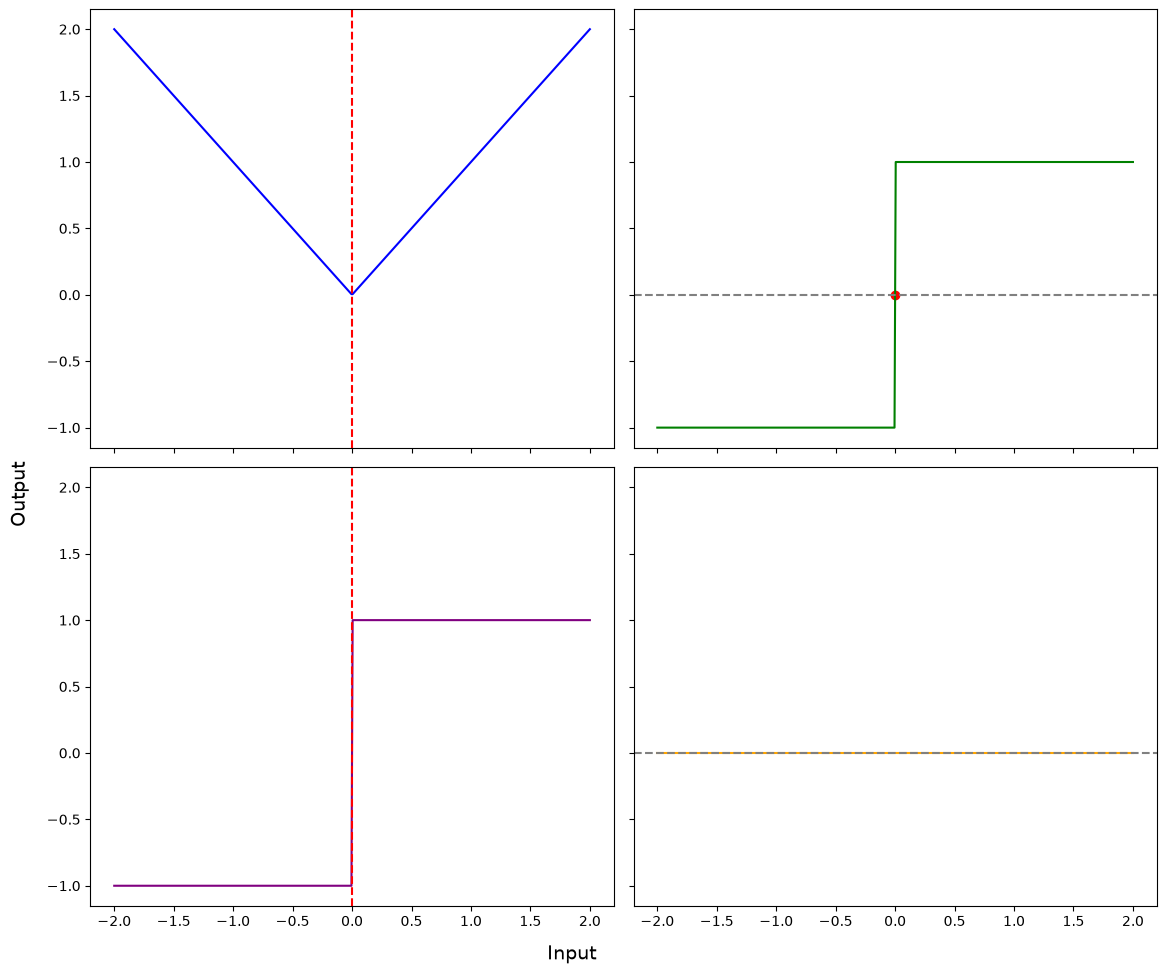

In [3]:
import os
import numpy as np
import matplotlib.pyplot as plt

def plot_non_differentiable_functions():
    x = np.linspace(-2, 2, 400)

    fig, axs = plt.subplots(2, 2, figsize=(12, 10), sharex=True, sharey=True)

    # |x| Function
    abs_y = np.abs(x)
    axs[0, 0].plot(x, abs_y, color='blue')
    axs[0, 0].axvline(0, color='red', linestyle='--')

    # Derivative of |x|
    derivative = np.sign(x)
    axs[0, 1].plot(x, derivative, color='green')
    axs[0, 1].scatter([0], [0], color='red')  # Show that derivative is zero at x=0
    axs[0, 1].axhline(0, color='gray', linestyle='--')

    # Sign Function
    sign_y = np.sign(x)
    axs[1, 0].plot(x, sign_y, color='purple')
    axs[1, 0].axvline(0, color='red', linestyle='--')

    # Gradient of sign(x)
    gradient_sign = np.zeros_like(x)
    axs[1, 1].plot(x, gradient_sign, color='orange')
    axs[1, 1].axhline(0, color='gray', linestyle='--')

    # Common labels
    fig.text(0.5, 0.04, 'Input', ha='center', va='center', fontsize=14)
    fig.text(0.04, 0.5, 'Output', ha='center', va='center', rotation='vertical', fontsize=14)

    plt.tight_layout(rect=[0.05, 0.05, 1, 1])
    plt.savefig(f"{os.environ.get('RPINN_OUTPUT_DIR', '.')}/Subgrad.pdf")
    plt.show()

# Llamar a la función para generar los gráficos en una misma figura con etiquetas comunes
plot_non_differentiable_functions()


# Objetivo 1

## Mezcla

Paper campaign (`RPINN/Data/v1-paper-run/Sinteticos`, 100 repetitions, IPOPT as the comparison solver): times, Figure 8 (`Toy.pdf`) and Figure 7 (`W.pdf`).

In [4]:
# Time of IPOPT and RPINN on the mixture model (Time2.pdf); RPINN.model_synthetic_data_.sintplot_tim

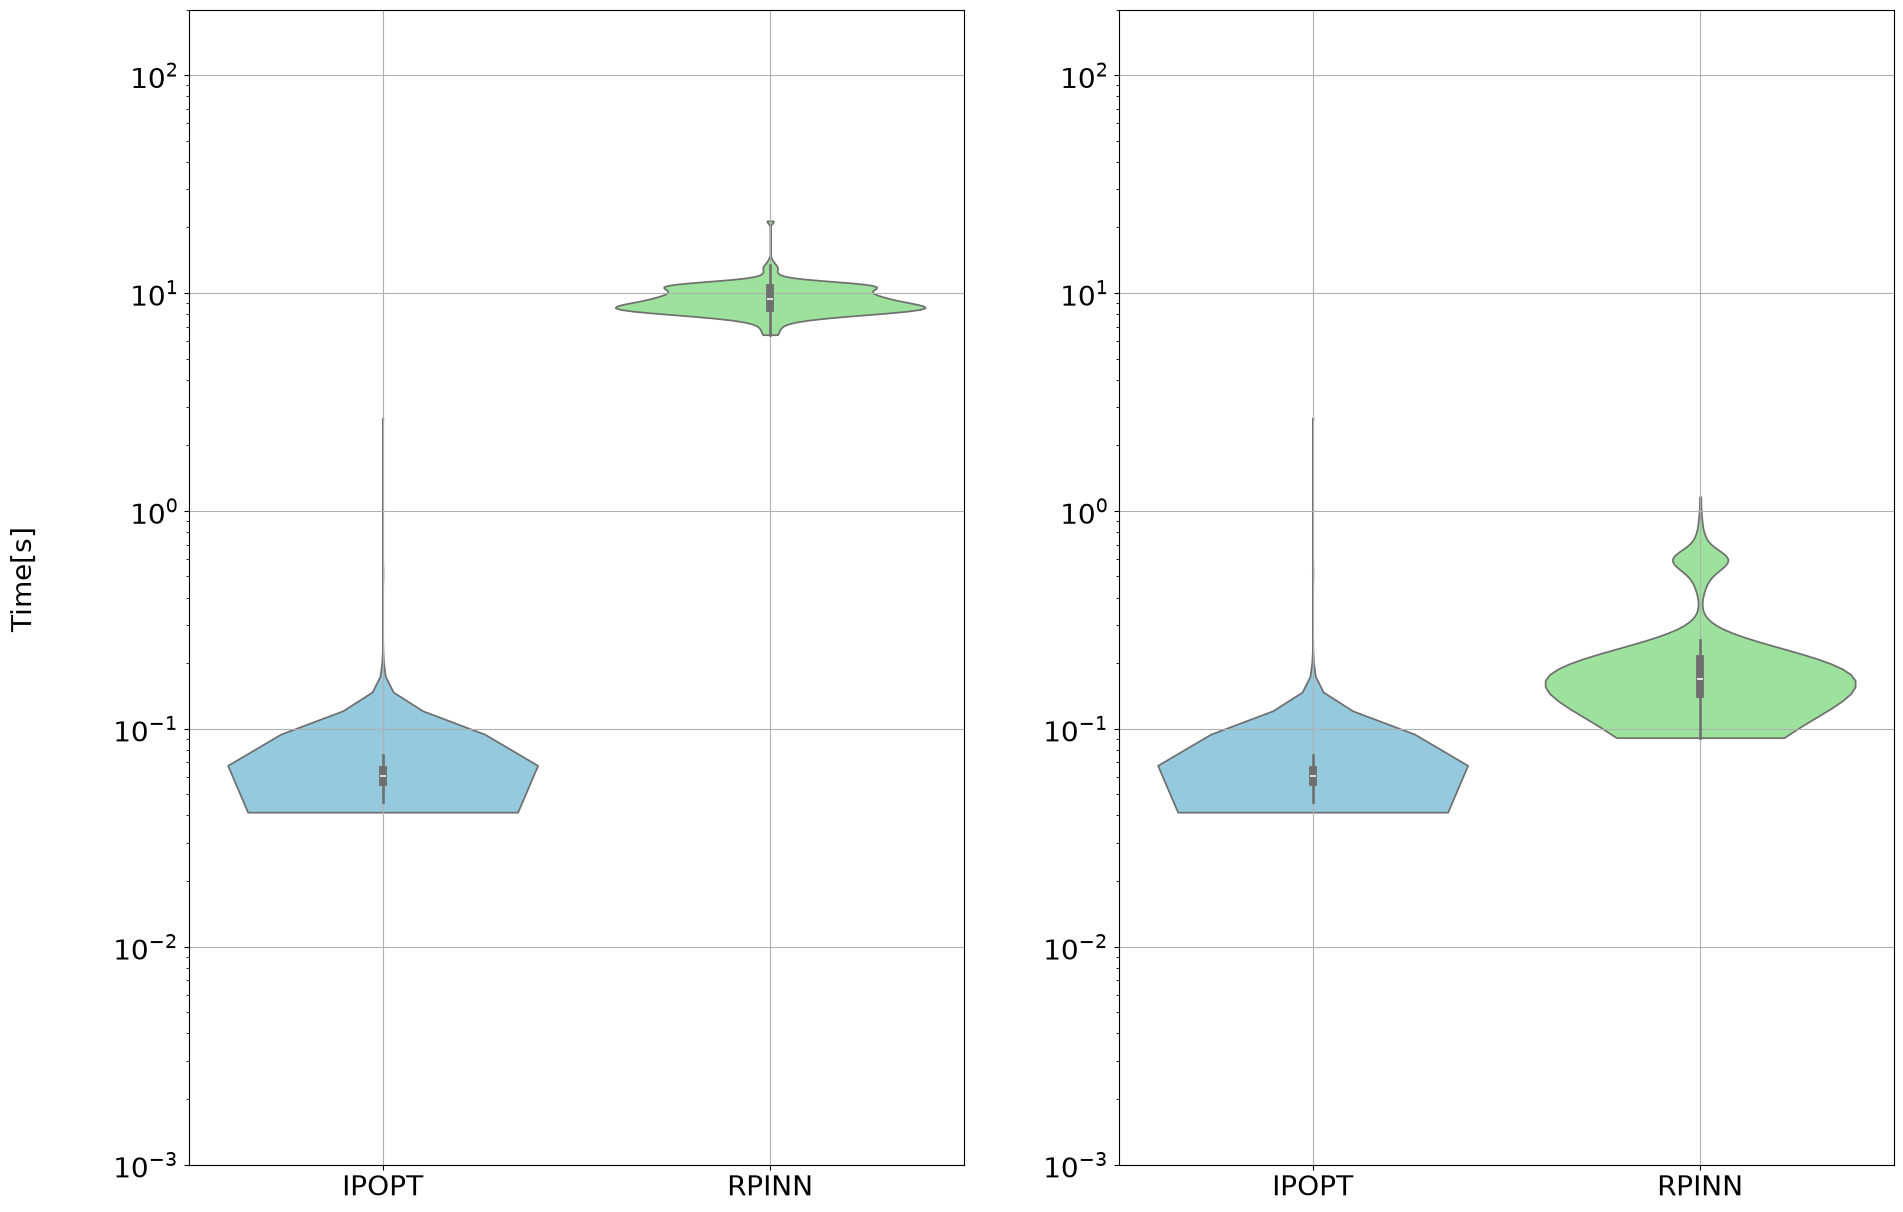

In [5]:
sintplot_tim()

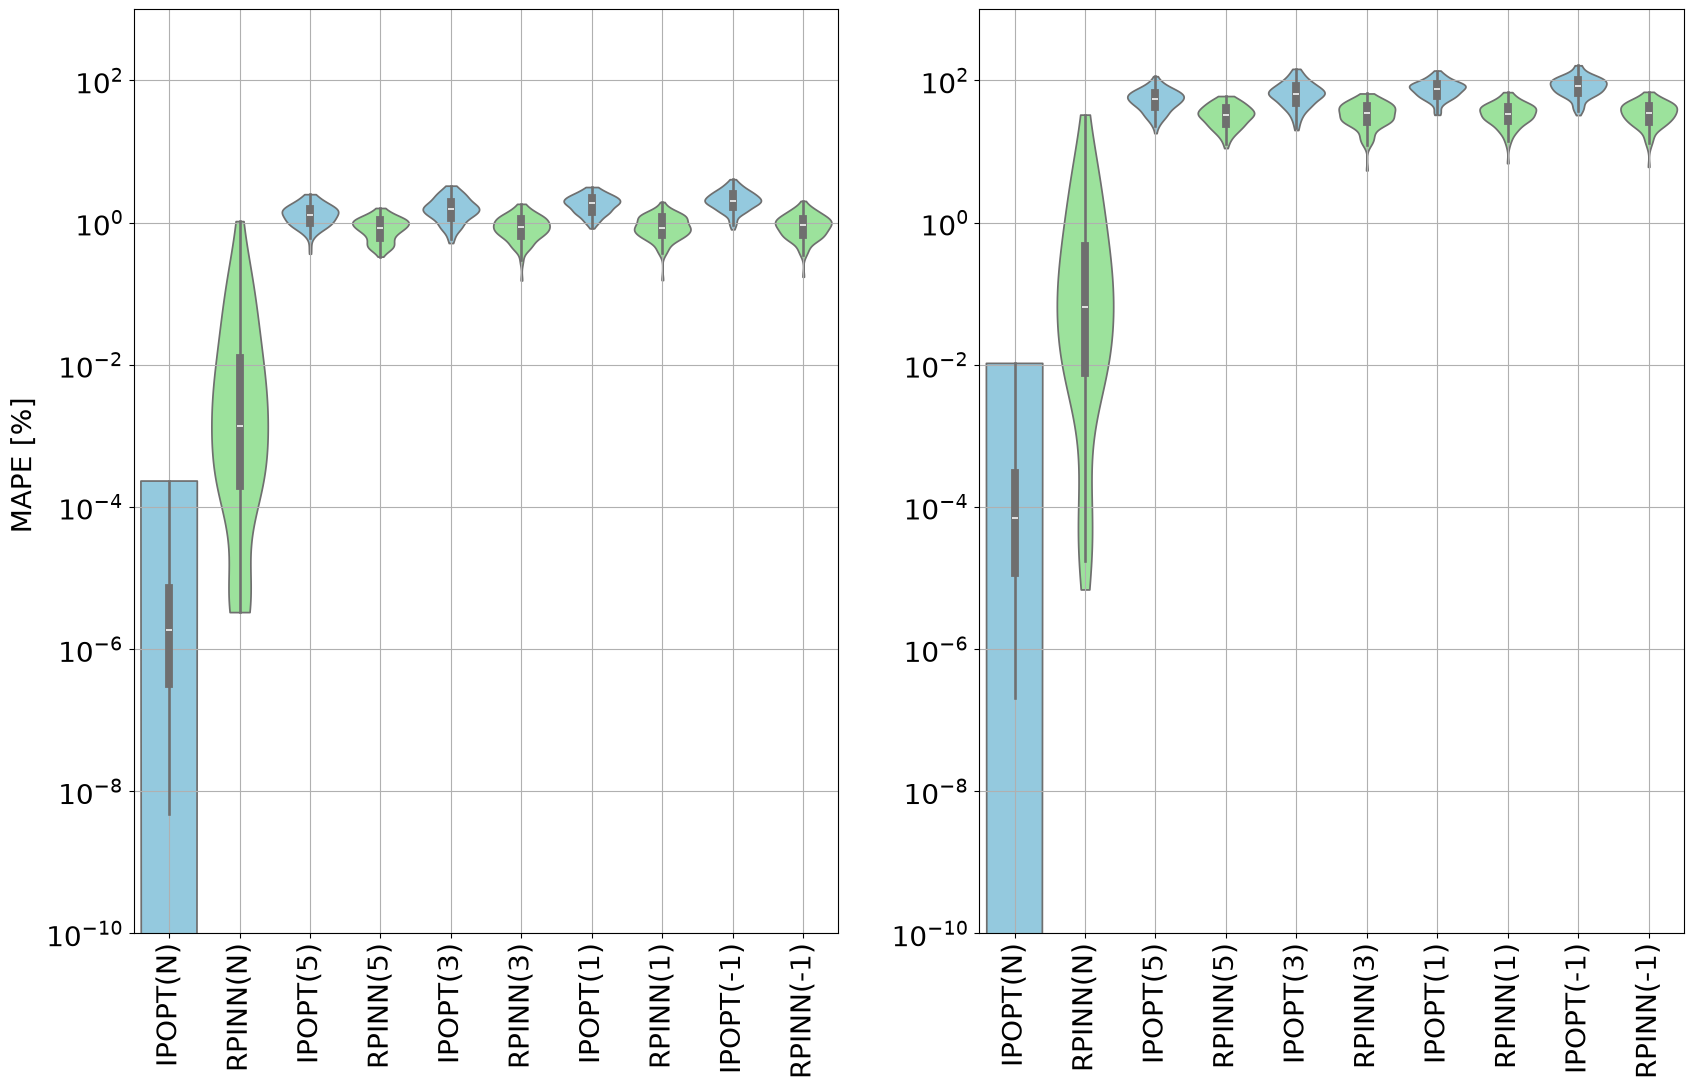

In [6]:
evv  = Evaluate()
evv.plot('IPOPT')  # paper Figure 8: output and weight MAPE per SNR level

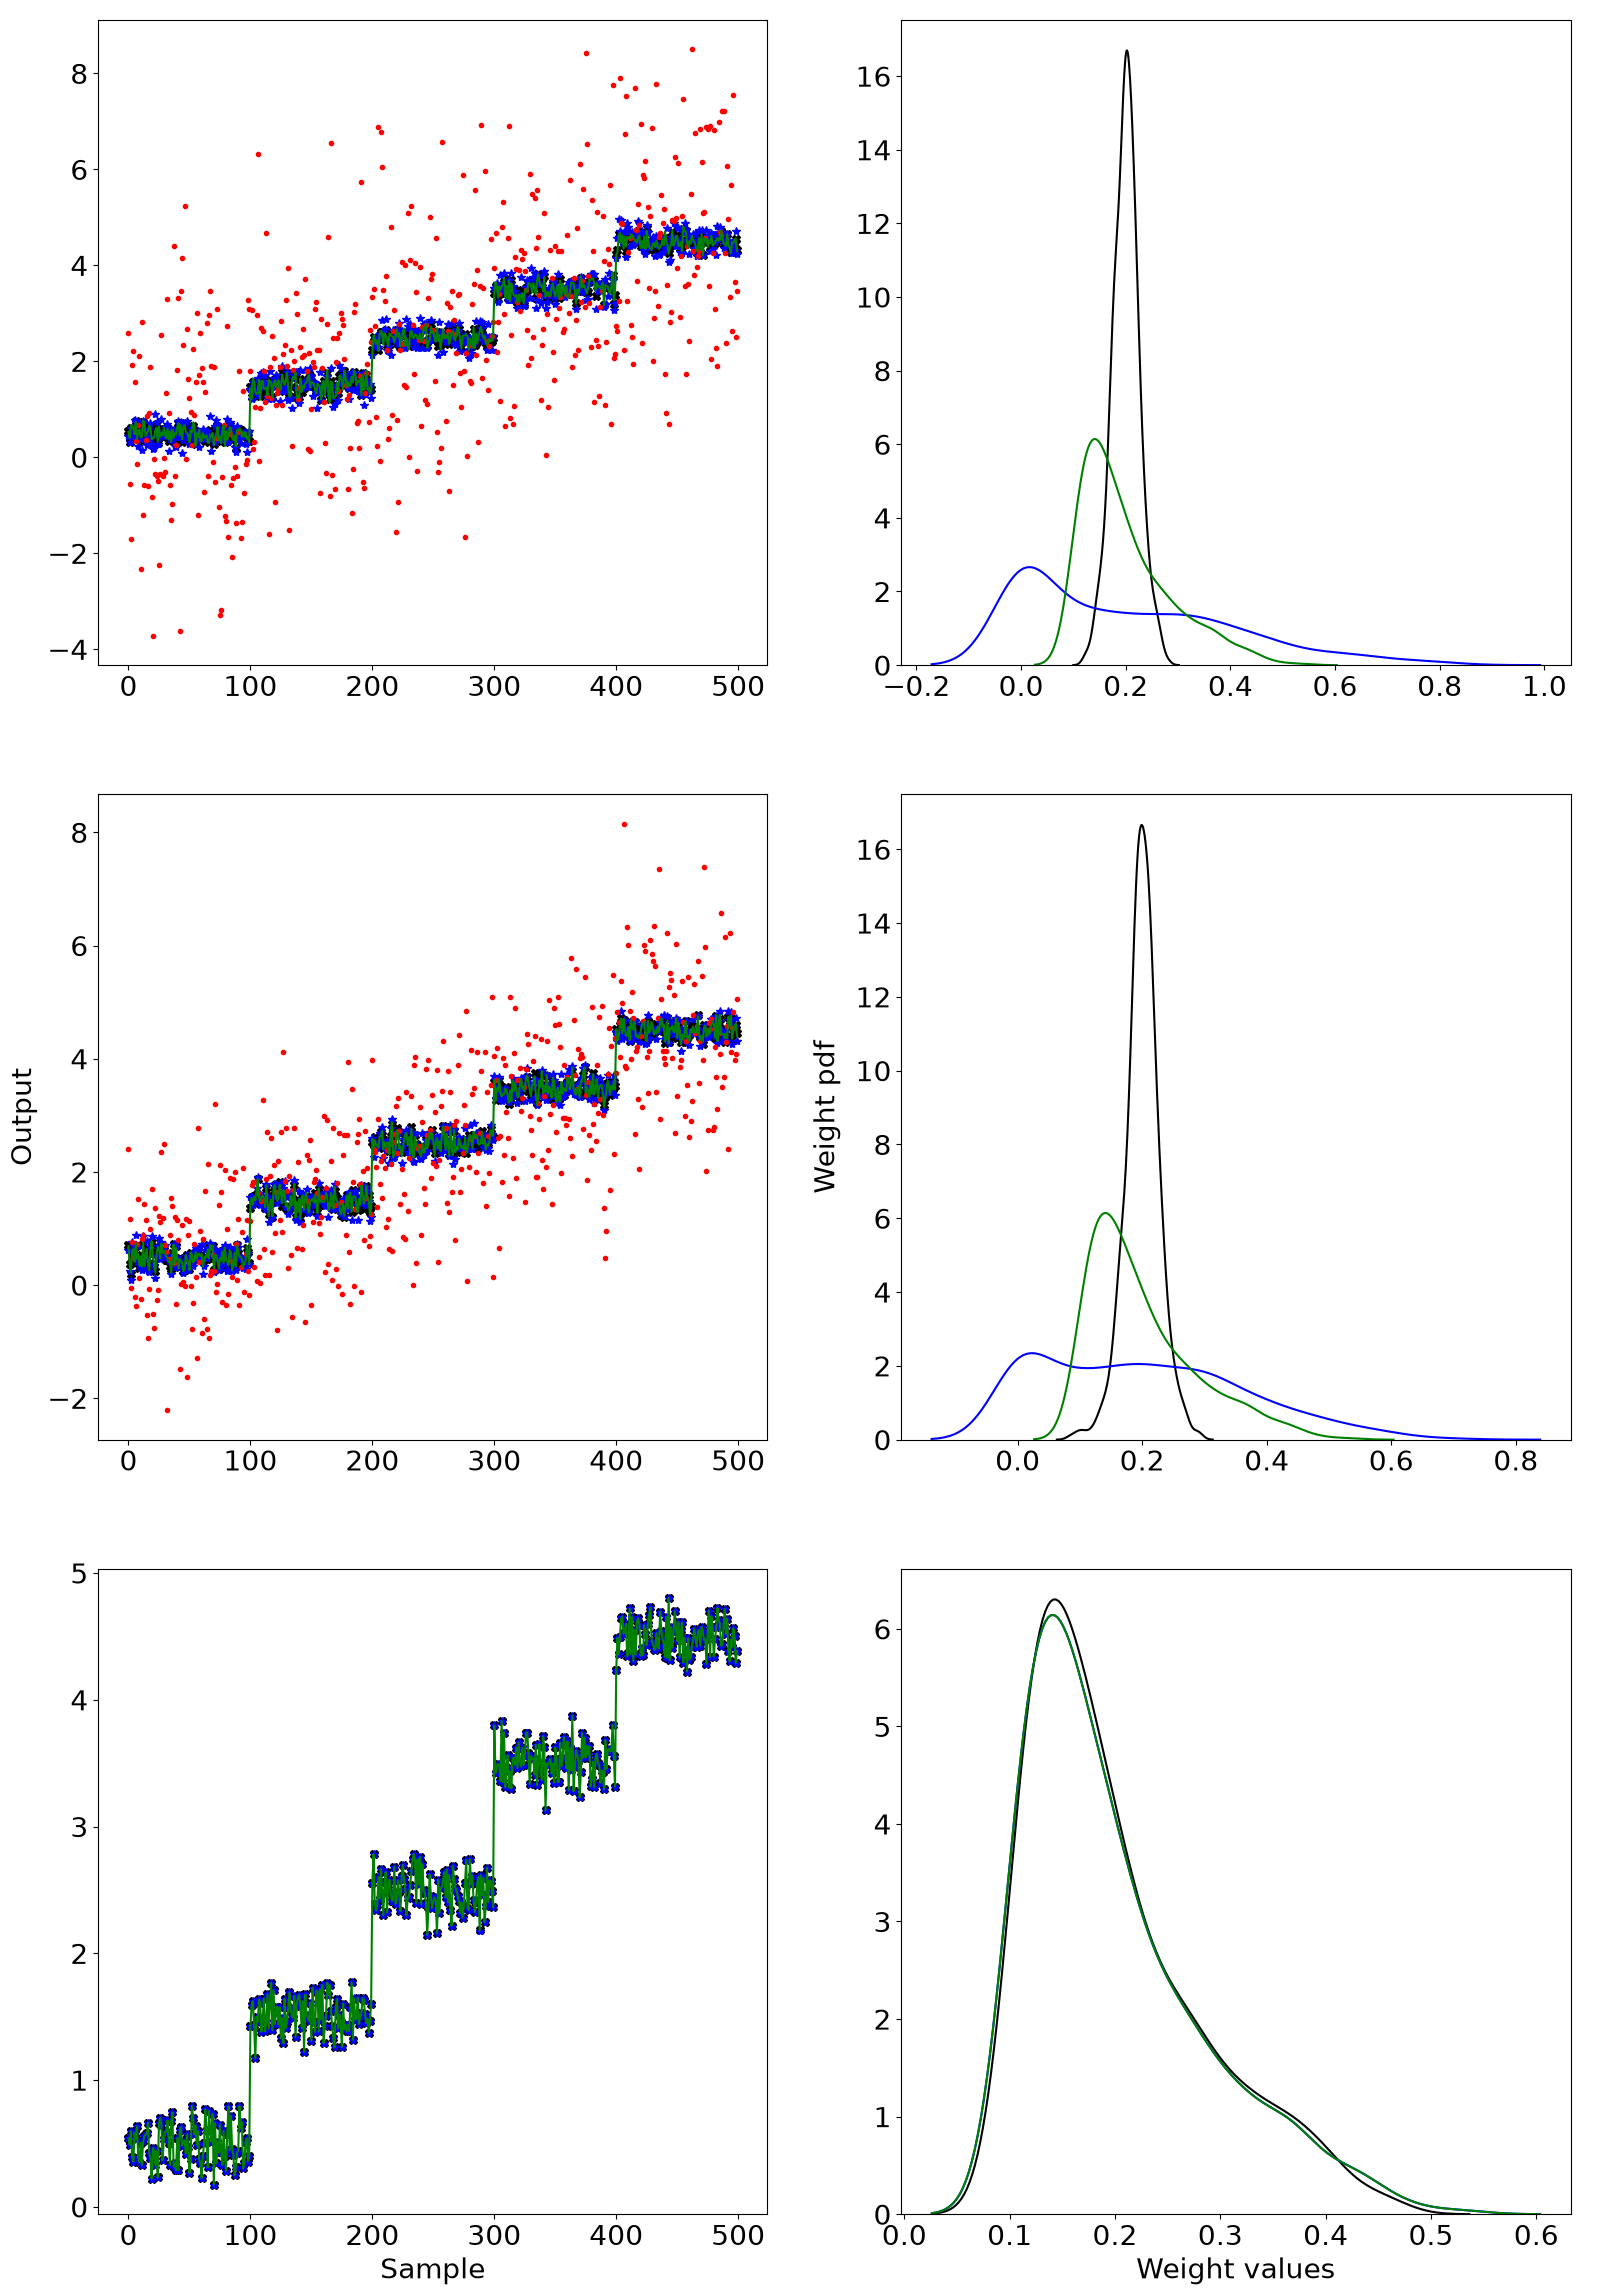

In [7]:
Weight()  # paper Figure 7: SNR -1 dB, 3 dB and noise-free

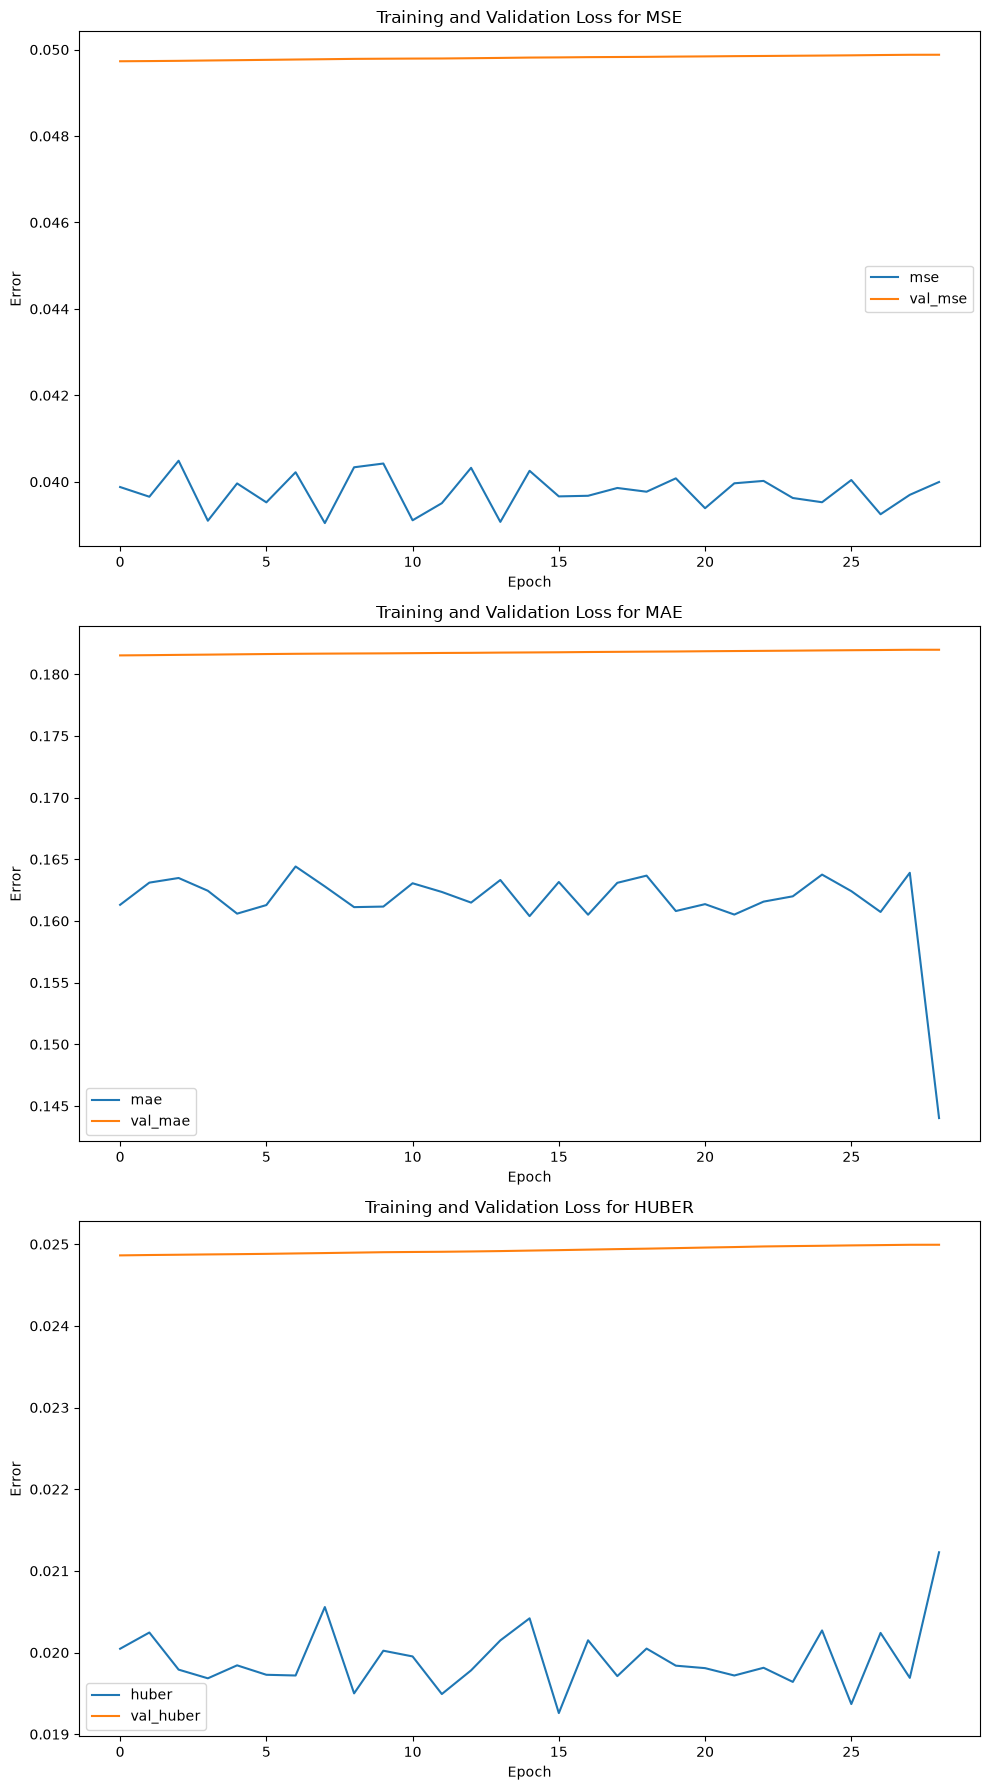

In [8]:
# 2024 thesis data: training with the mse, mae and huber losses (the paper campaign trains huber only)
a=evv.history_plot()

## Moscas

2024 thesis data (`RPINN/Data/Sintéticos`); not part of the paper.

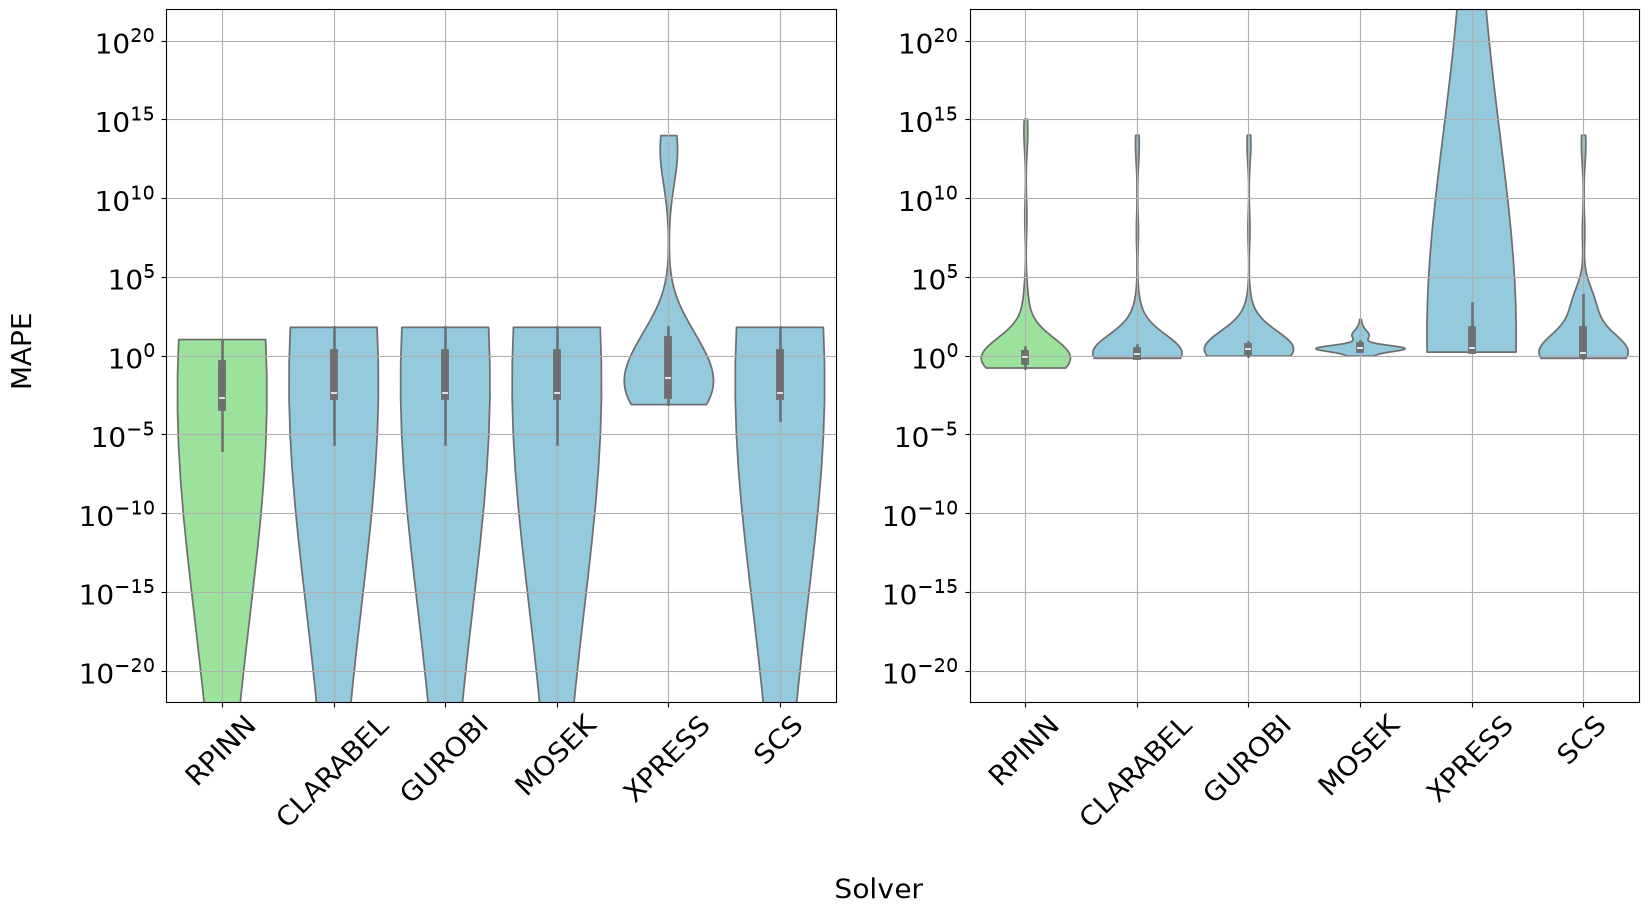

In [9]:
fly=FlyEvaluate().plot_results(SYN_2024)

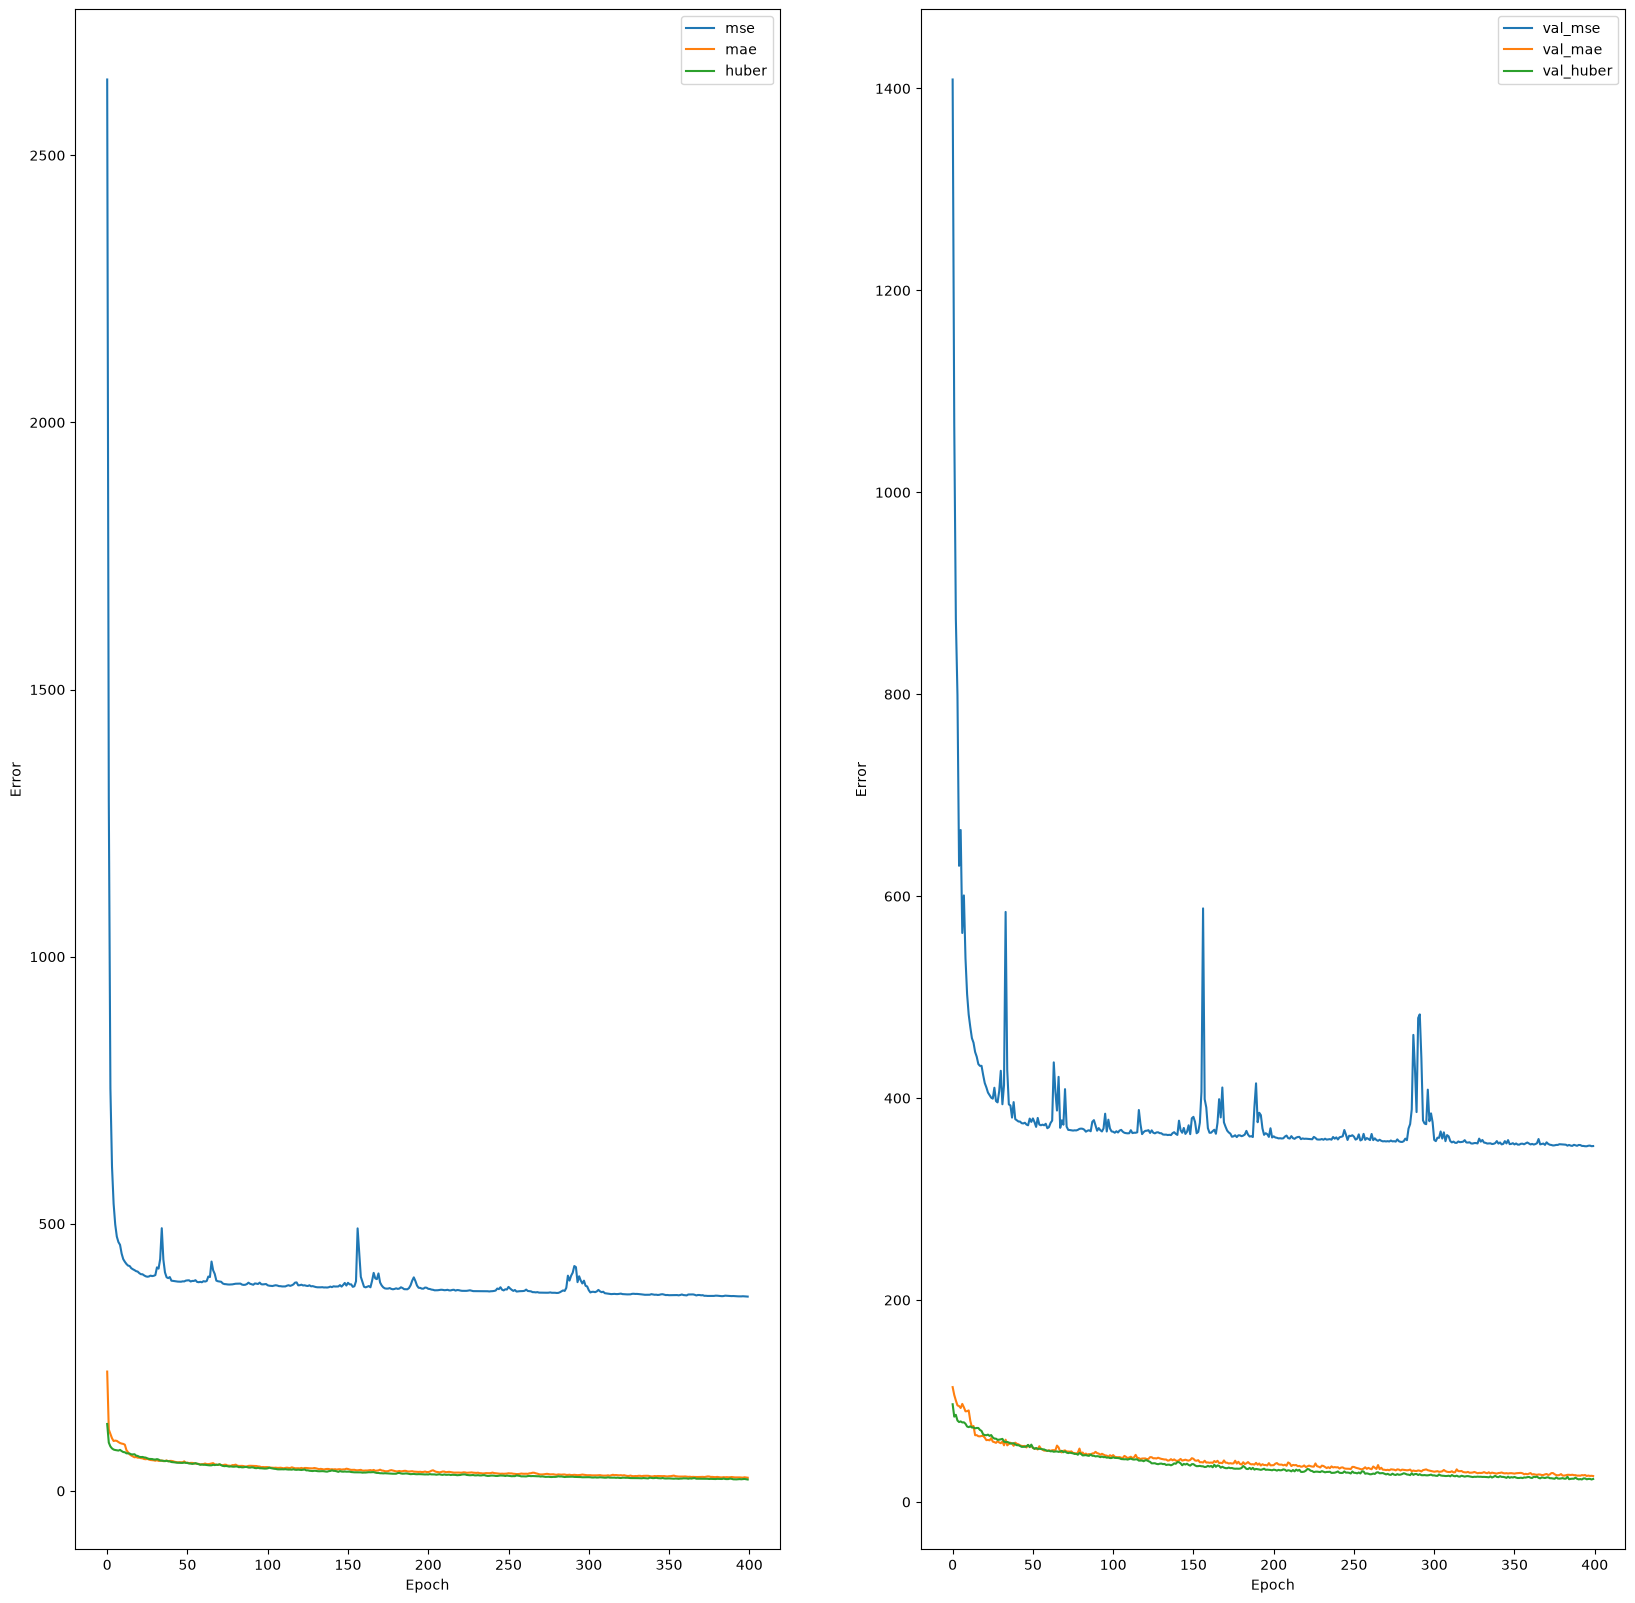

In [10]:
FlyEvaluate().history_plot_loss(SYN_2024)

#Objetivo 2

The loss-function comparison (`loss_val`) is 2024 thesis data (`RPINN/Data/Registro`). Everything after it reads the paper campaign (`RPINN/Data/v1-paper-run`): Figure 10 (`RGAS8.pdf`), Figure 11 (`LIM.pdf`), non-convergence of IPOPT and outliers.

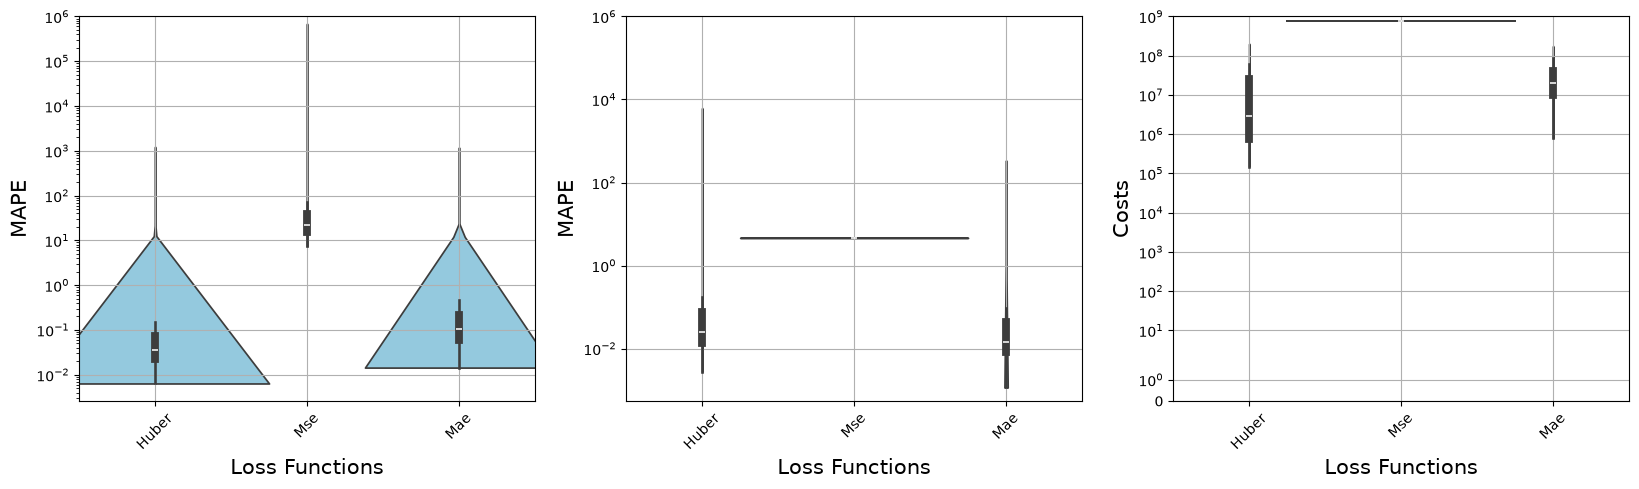

In [11]:
loss_val()  # 2024 thesis data

In [12]:
#dynamic_val(tip='D')

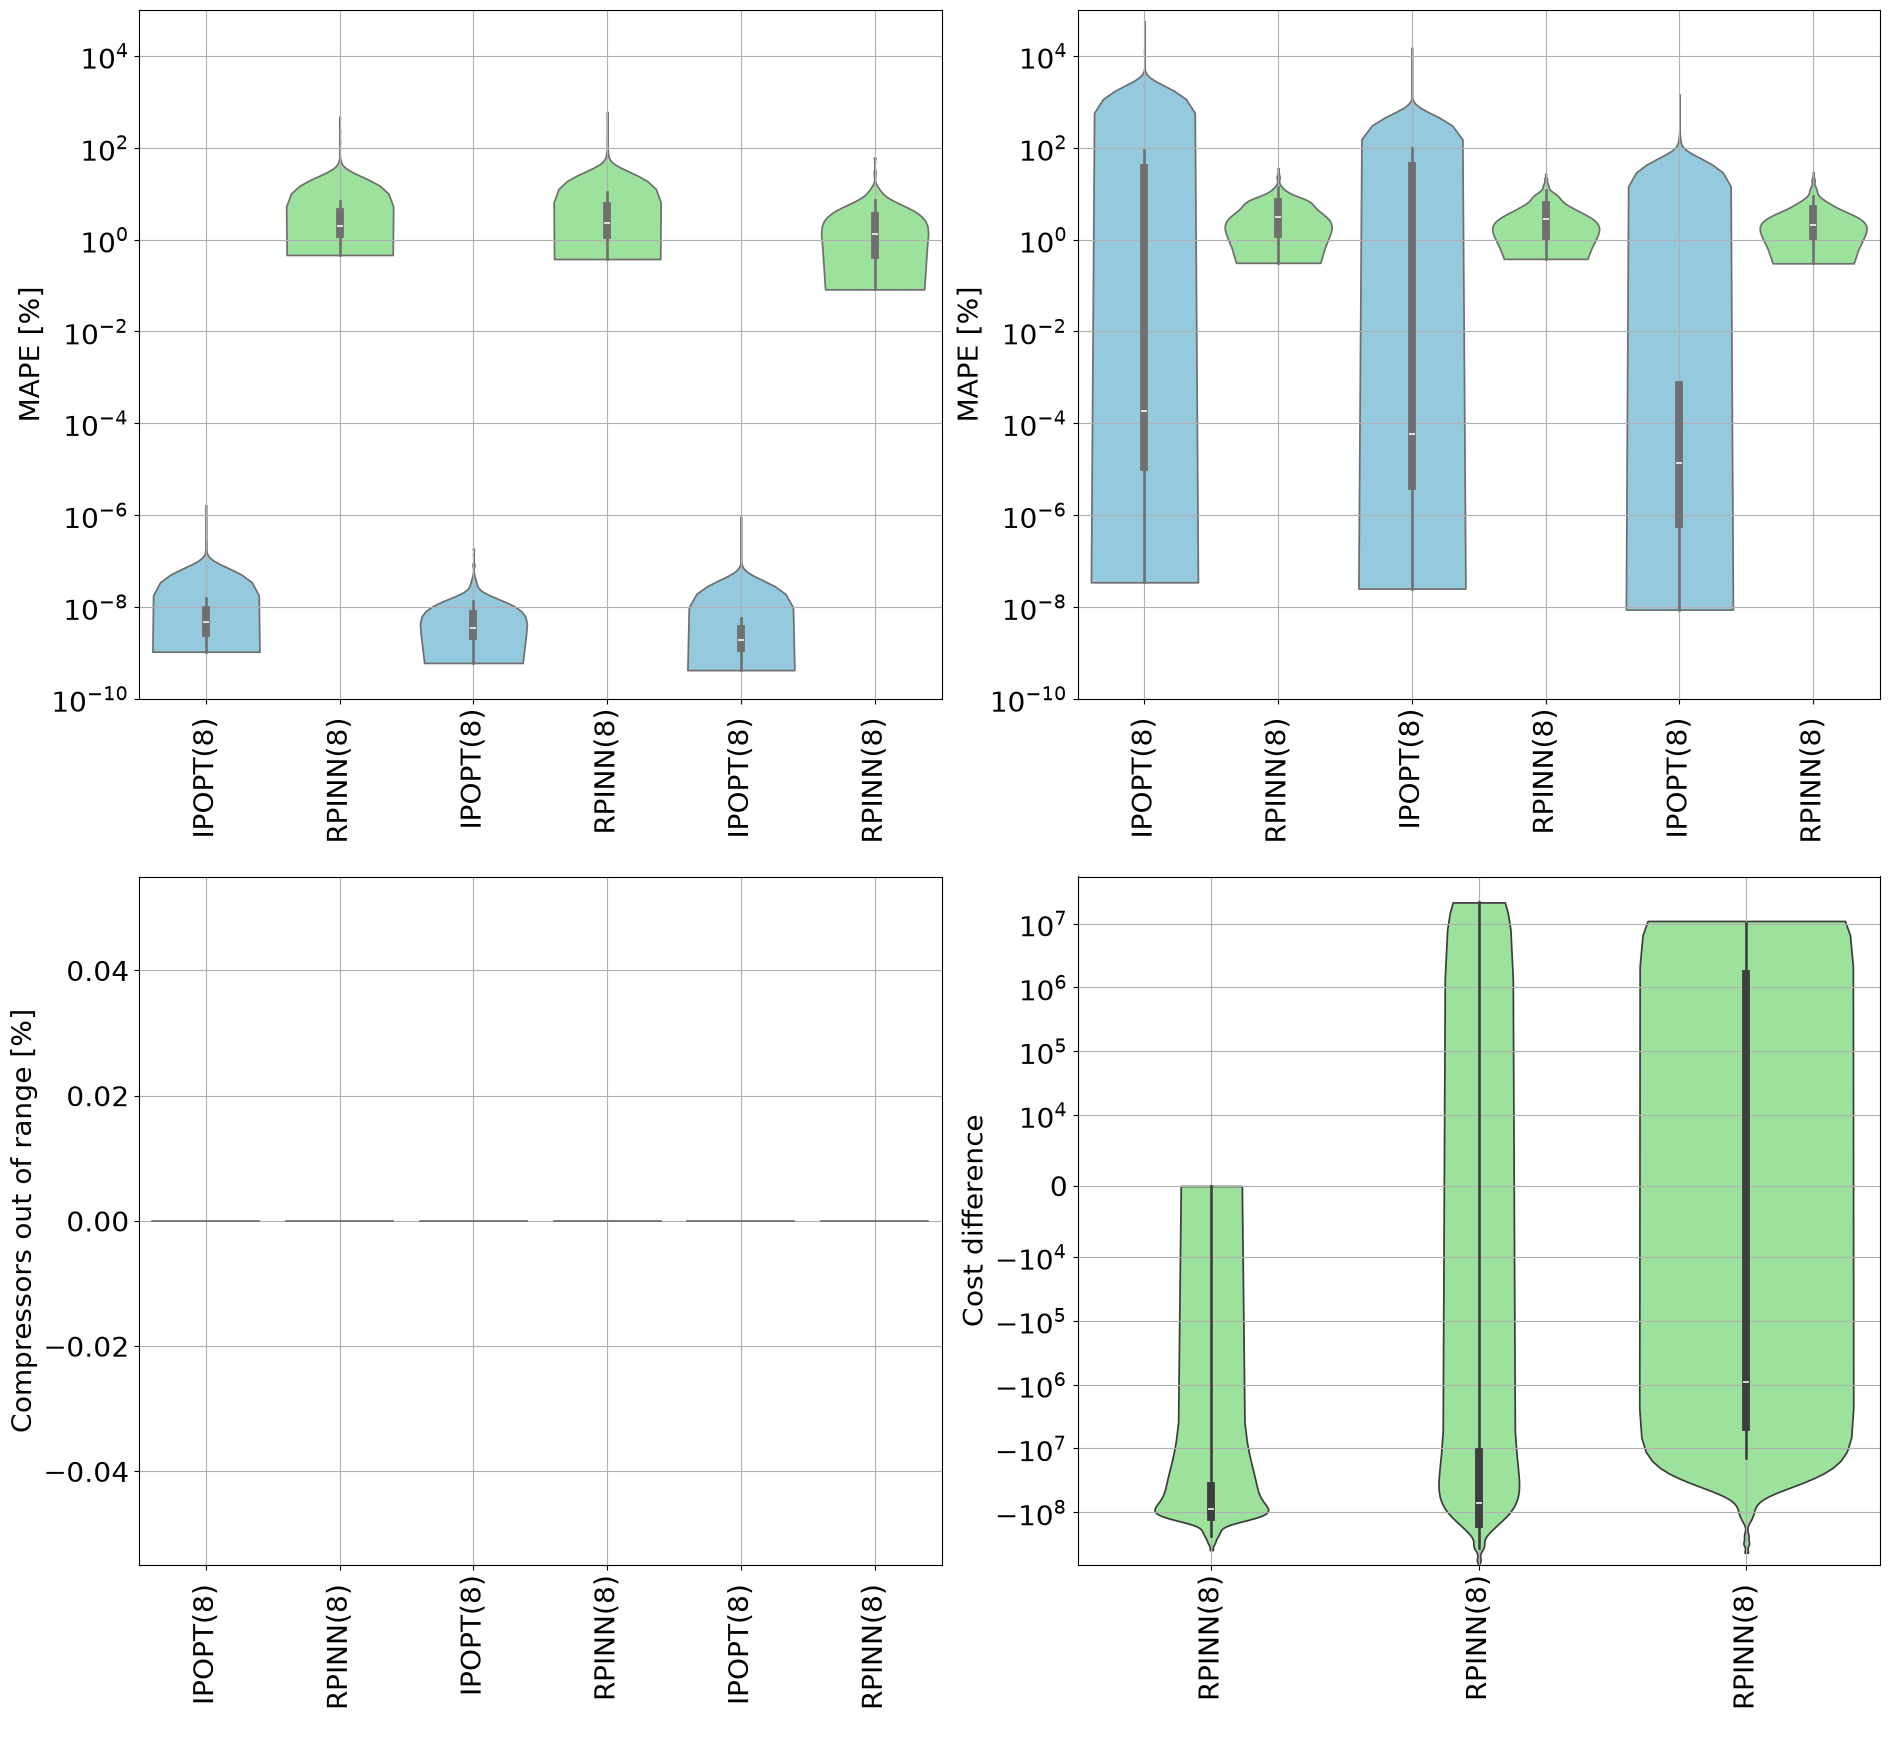

In [13]:
RGAS()

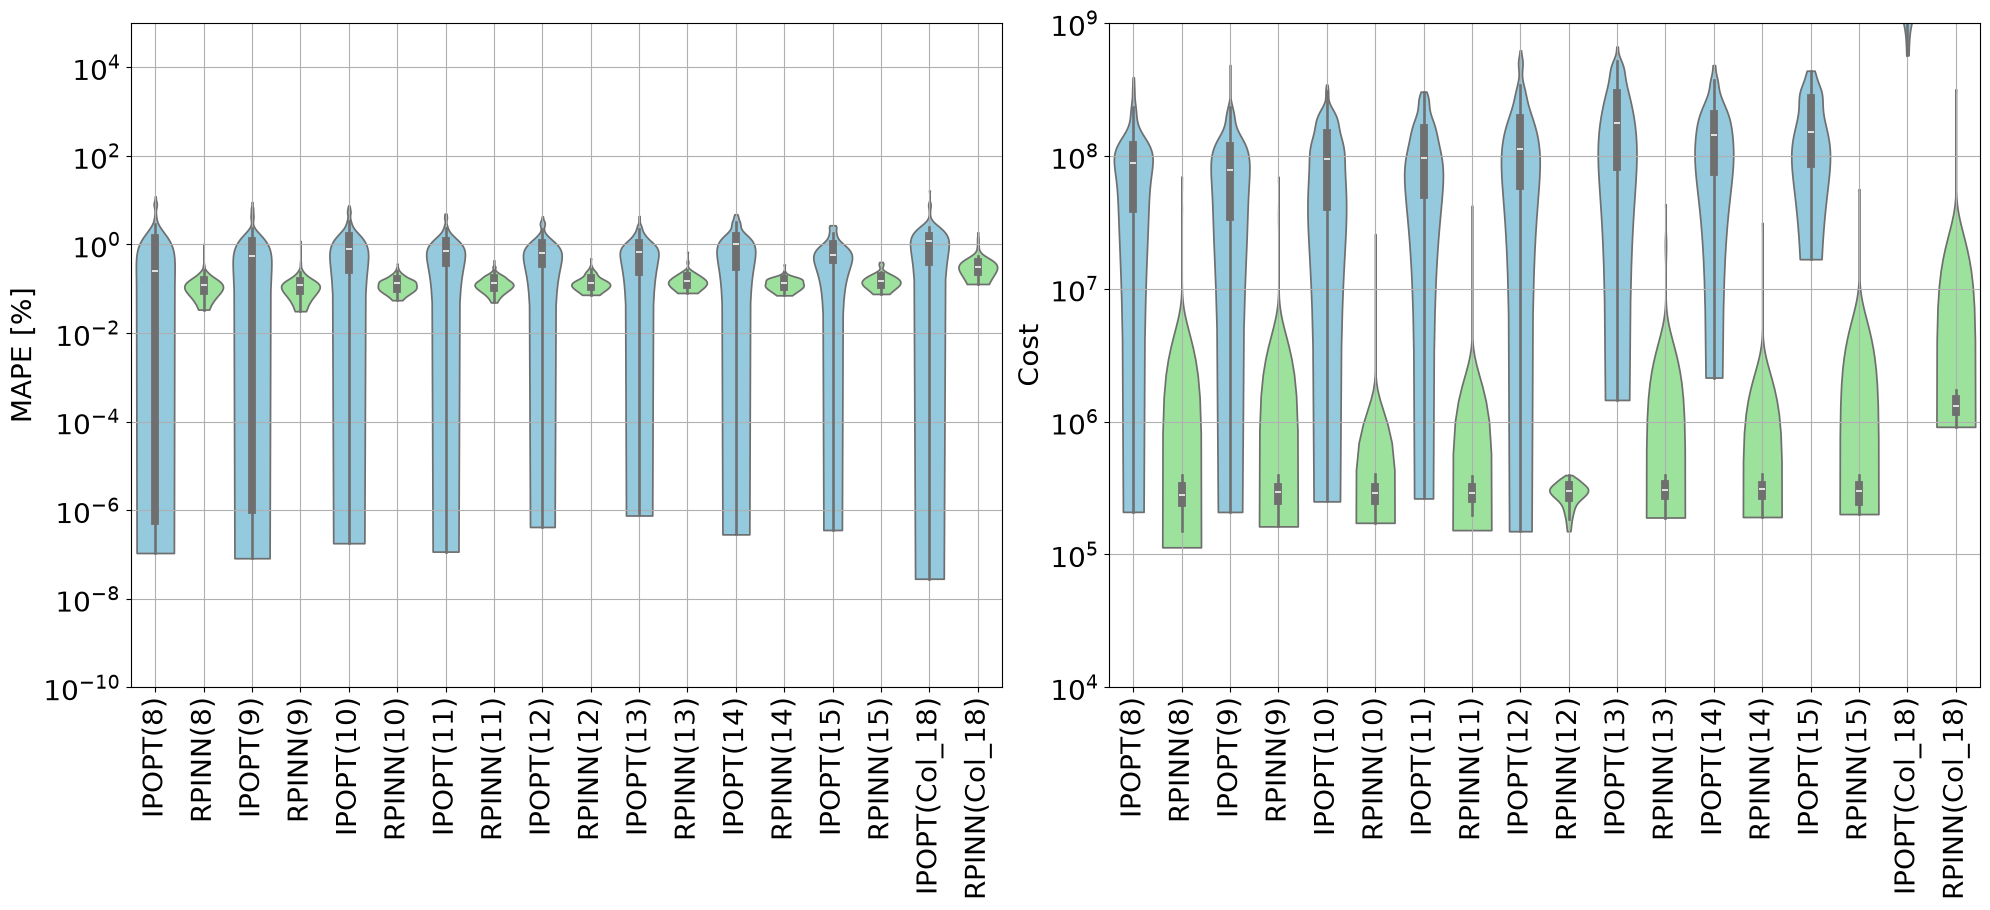

In [14]:
Balance,Weymouth,PjPi,Costos=ng_case_evaluate(s=1,tip1='S',tip2='MAE',plotb=True,selec='A')

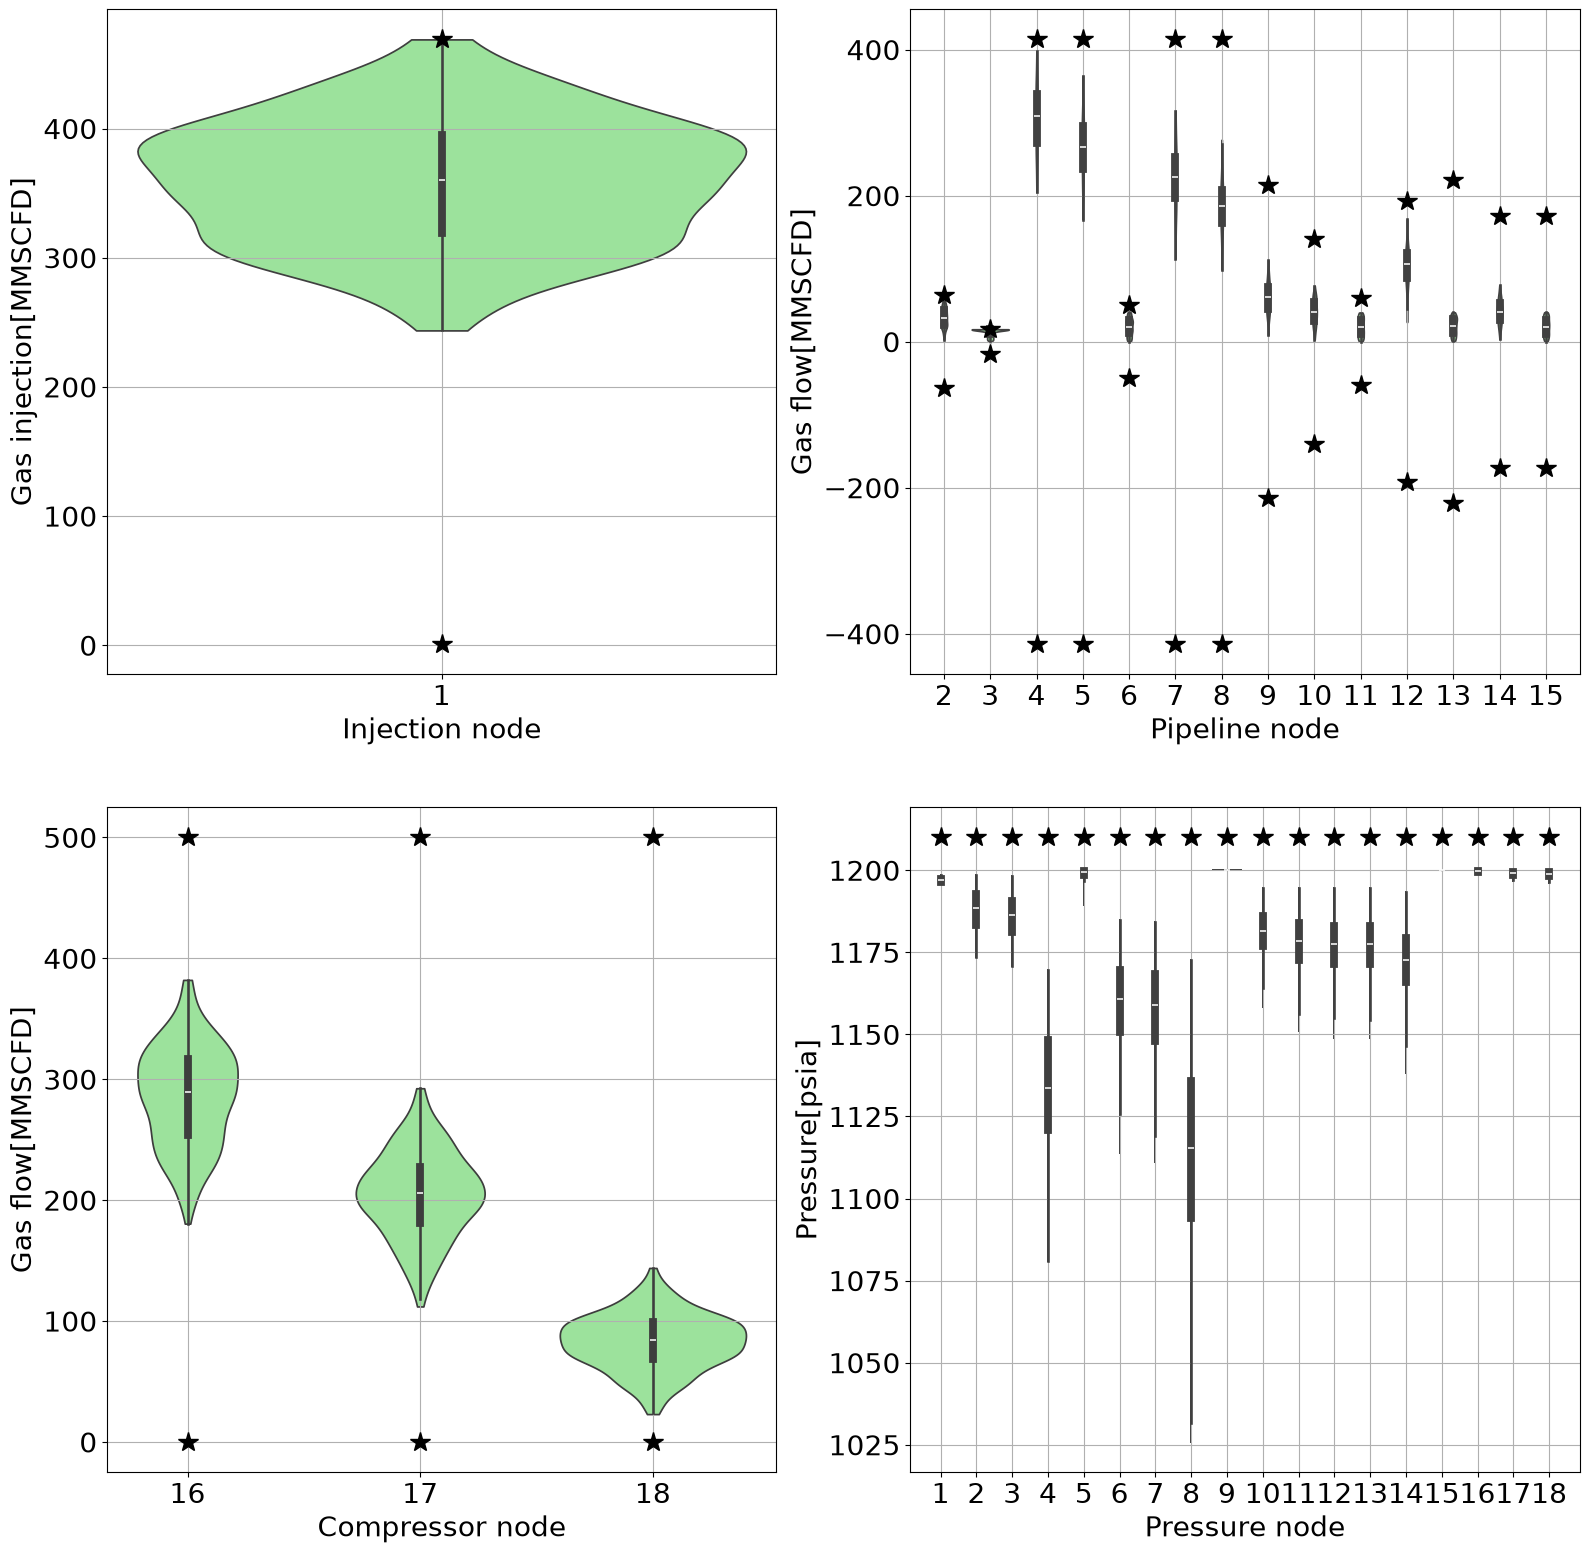

In [15]:
Pe=bounded(s=1,im=8,tip='S')

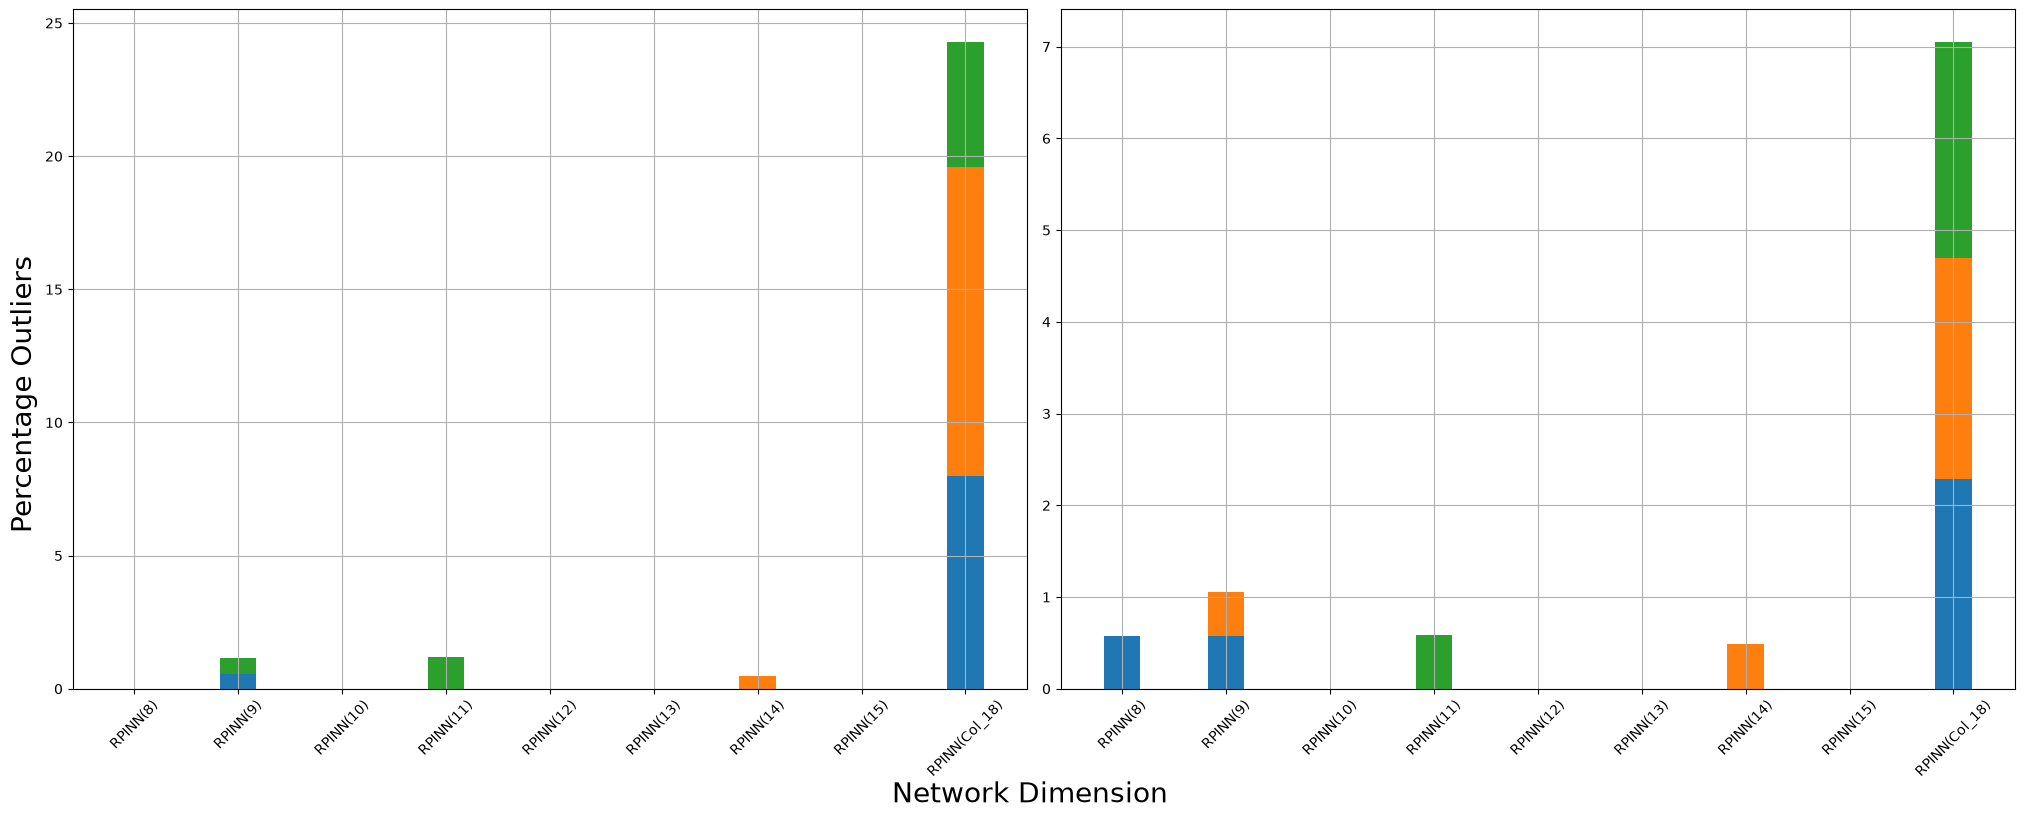

In [16]:
Balance1,Weymouth1,PjPi1,Costos1=ng_case_evaluate(s=1,tip1='S',tip2='MAE',plotb=False)
Balance2,Weymouth2,PjPi2,Costos2=ng_case_evaluate(s=1,tip1='M',tip2='MAE',plotb=False)
Balance3,Weymouth3,PjPi3,Costos3=ng_case_evaluate(s=1,tip1='D',tip2='MAE',plotb=False)
dB1=Balance1[['RPINN(8)','RPINN(9)','RPINN(10)','RPINN(11)','RPINN(12)',
           'RPINN(13)','RPINN(14)','RPINN(15)','RPINN(Col_18)']]
columnas_red = dB1.columns
visualize_atipic([Balance1,Balance2,Balance3],[Weymouth1,Weymouth2,Weymouth3], columnas_red)

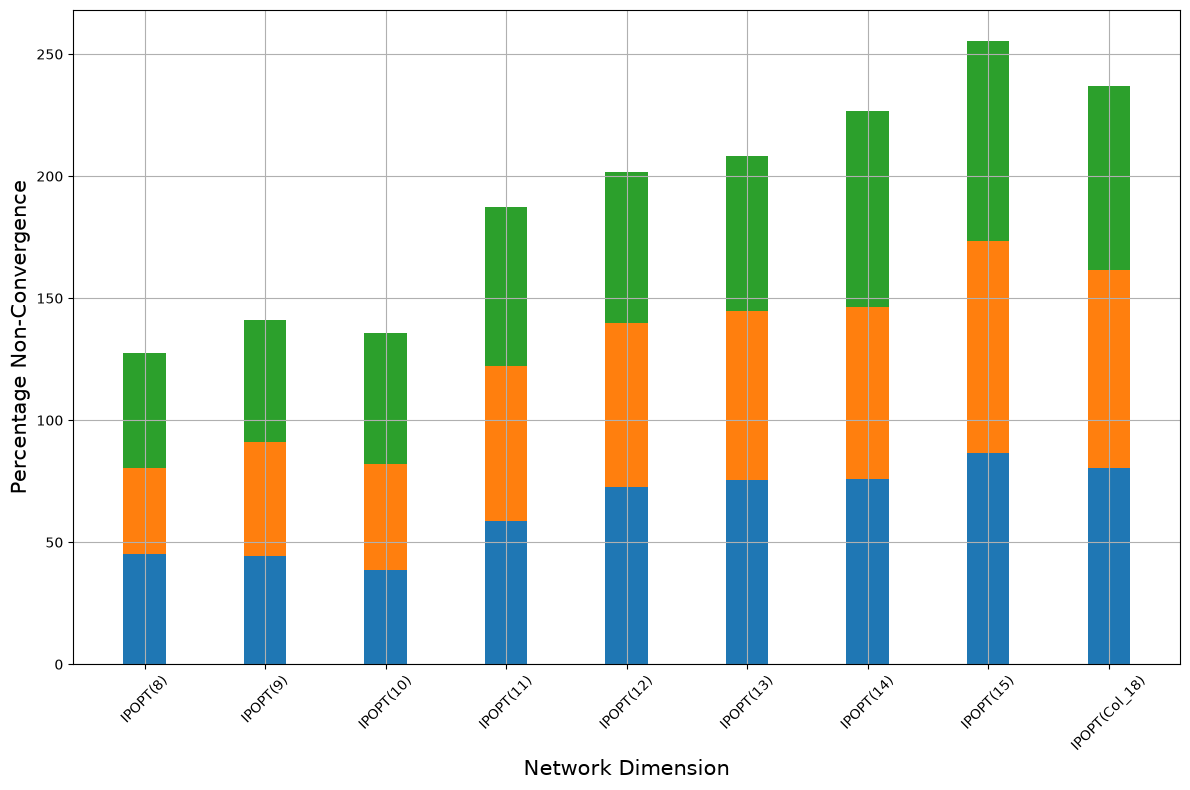

In [17]:
visualize_non_convergence(tips=['S','M', 'D'])

# Objetivo 3

Figure 12 (`Time.pdf`): training and prediction times measured in the same session as IPOPT.

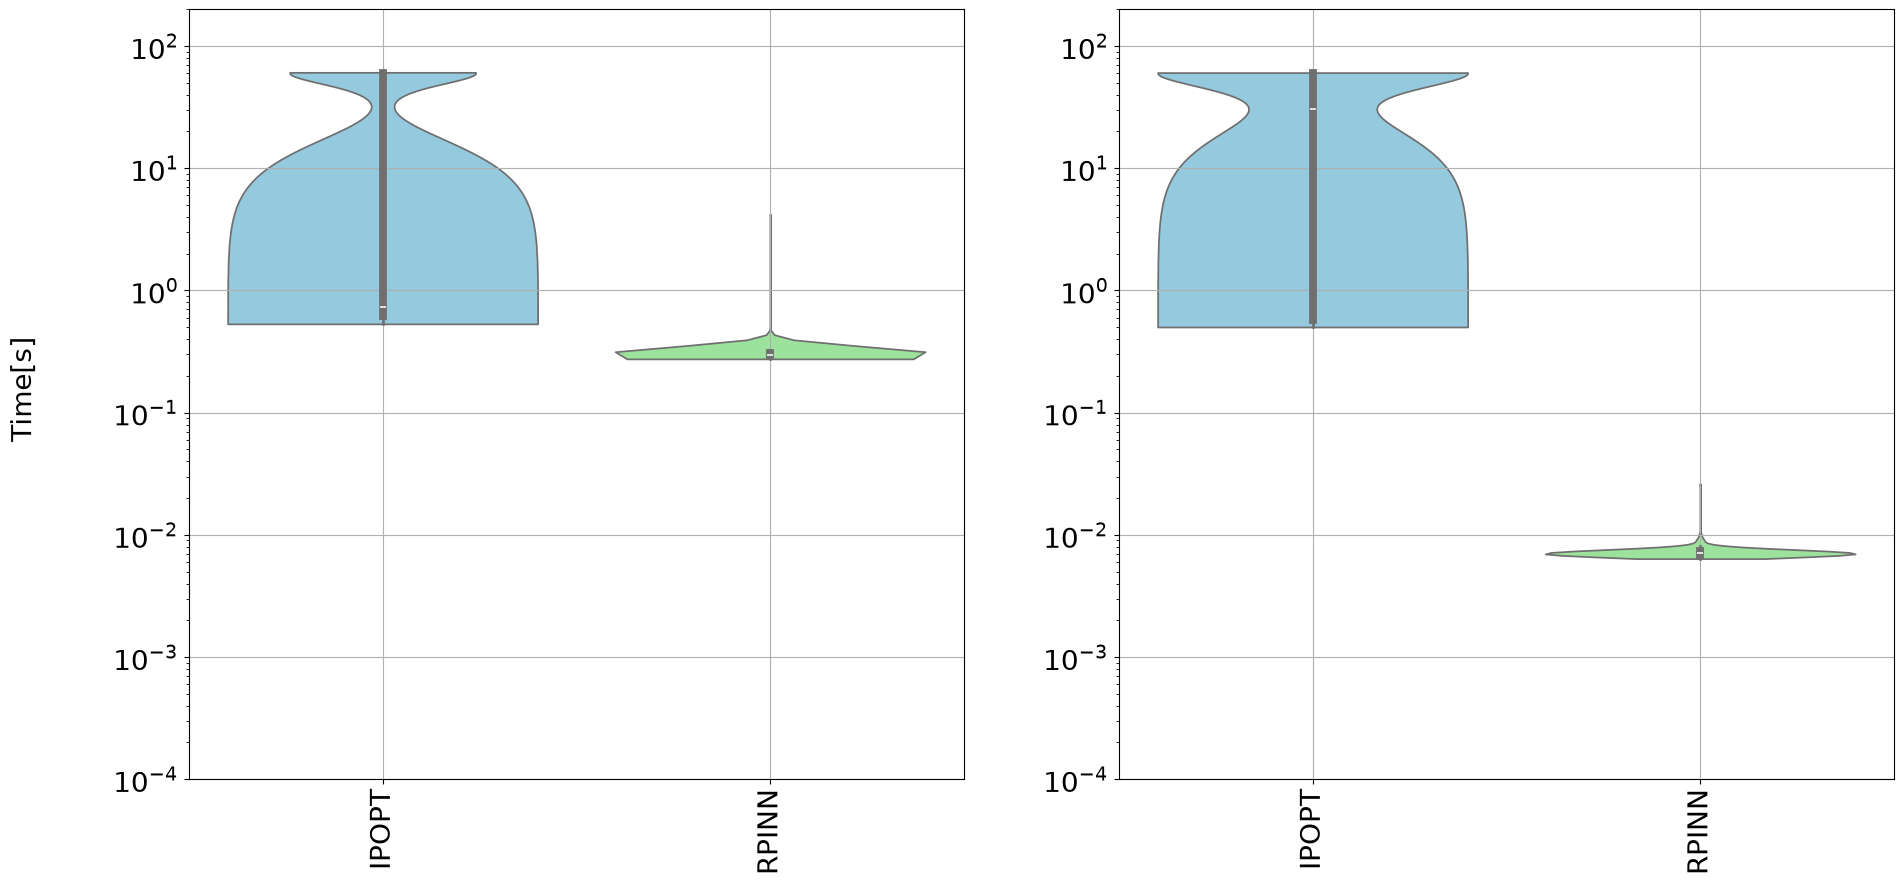

In [18]:
plot_time_p()

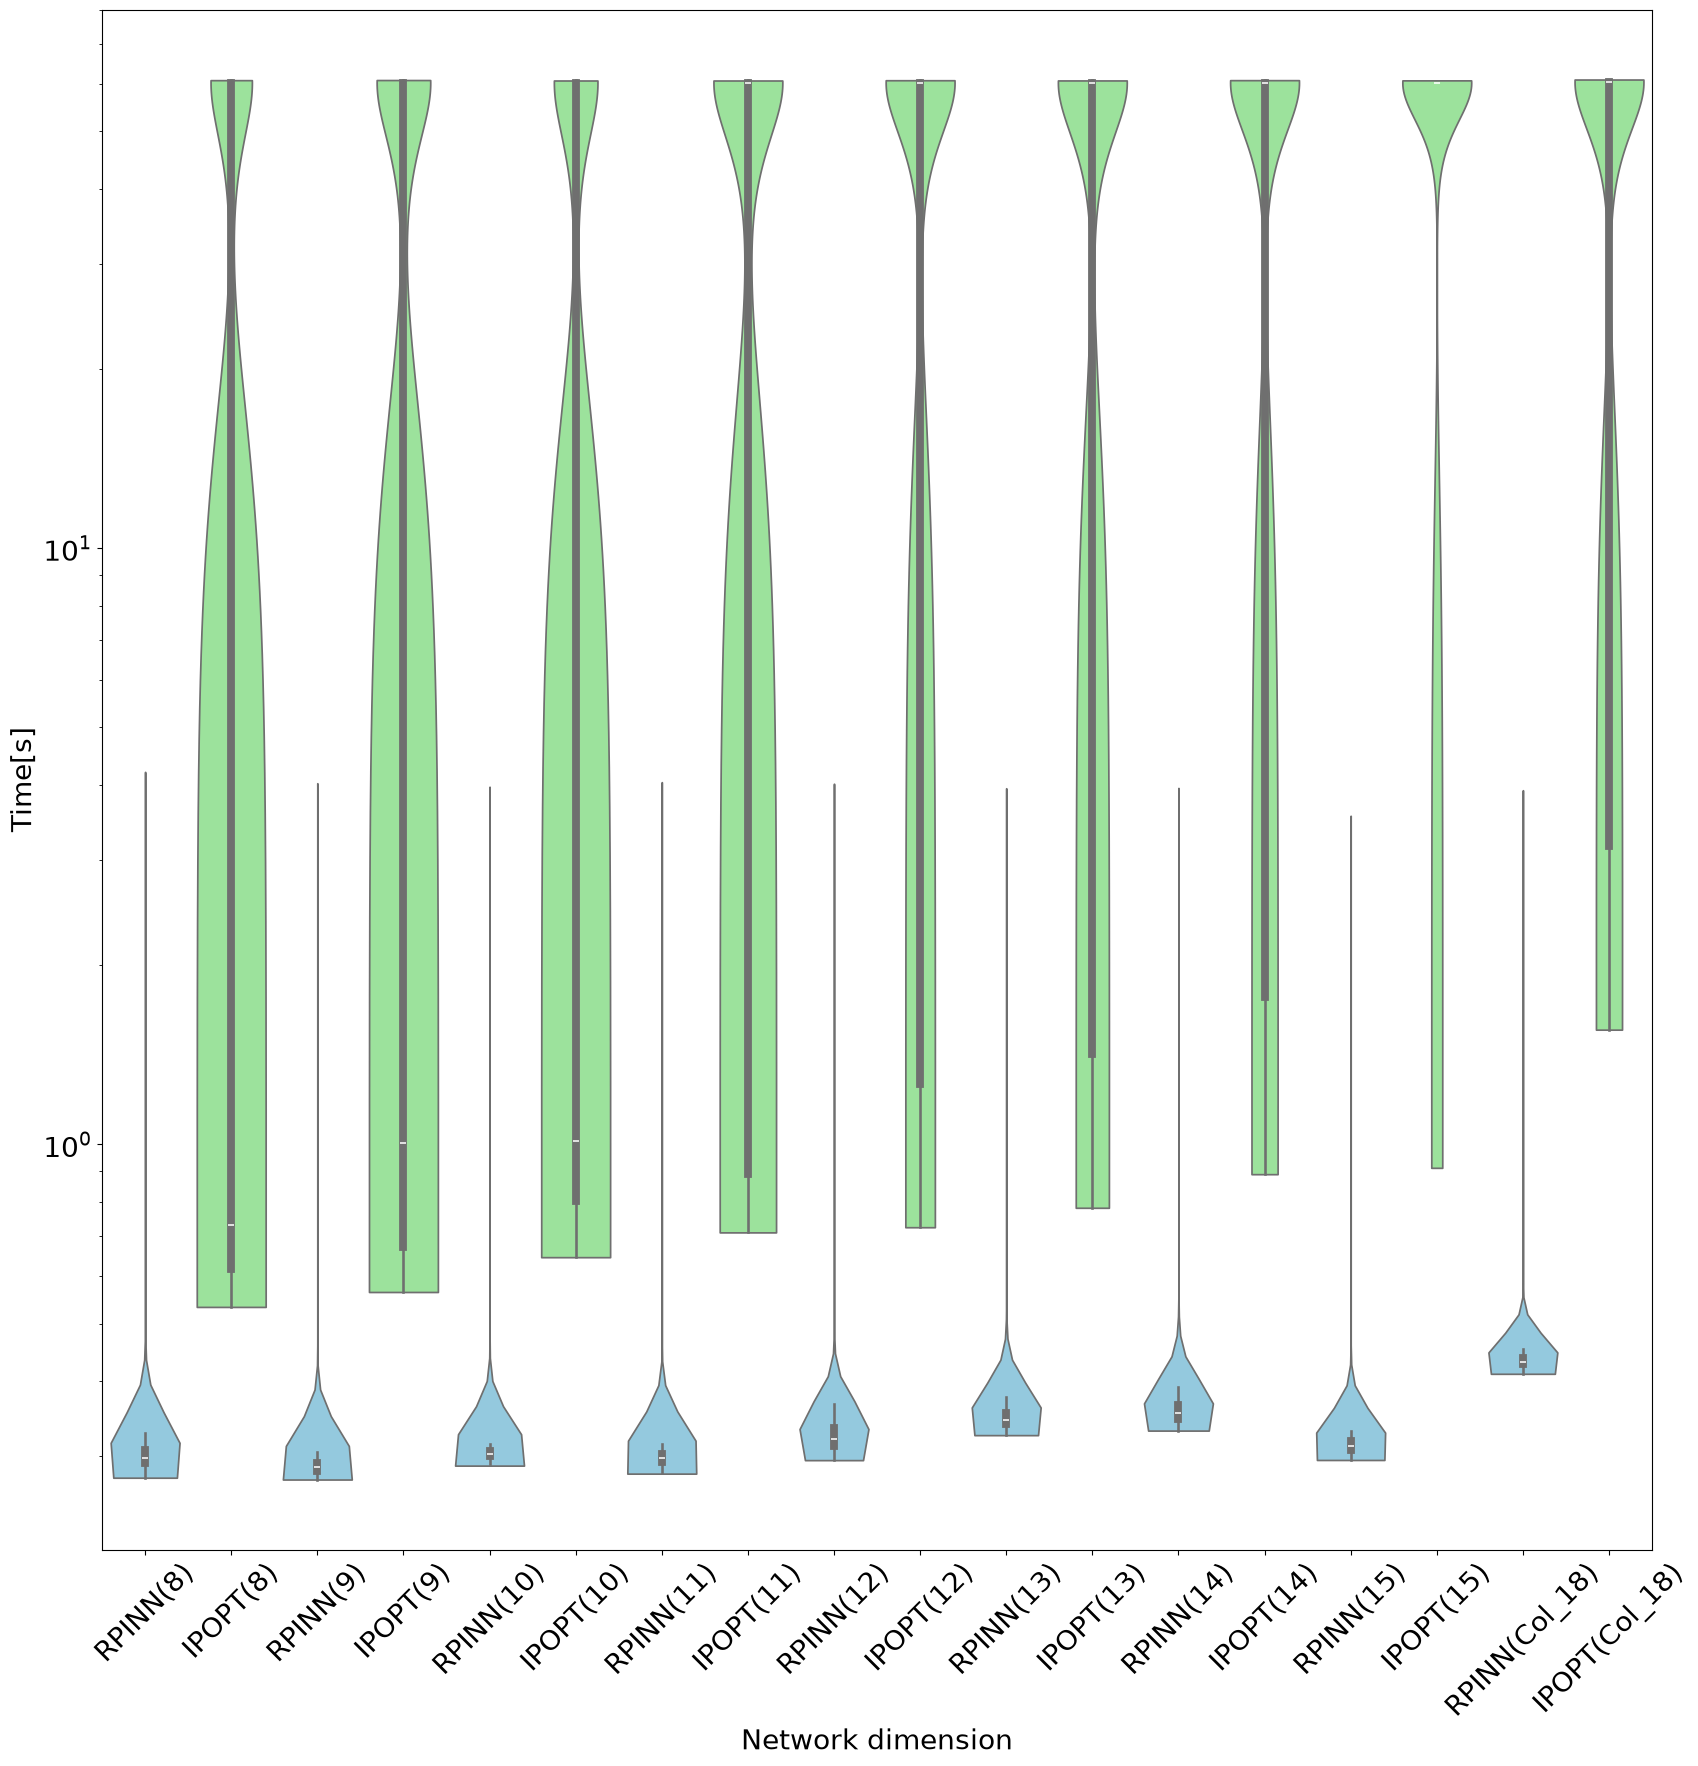

In [19]:
a=plot_time(s=1,tip='M')

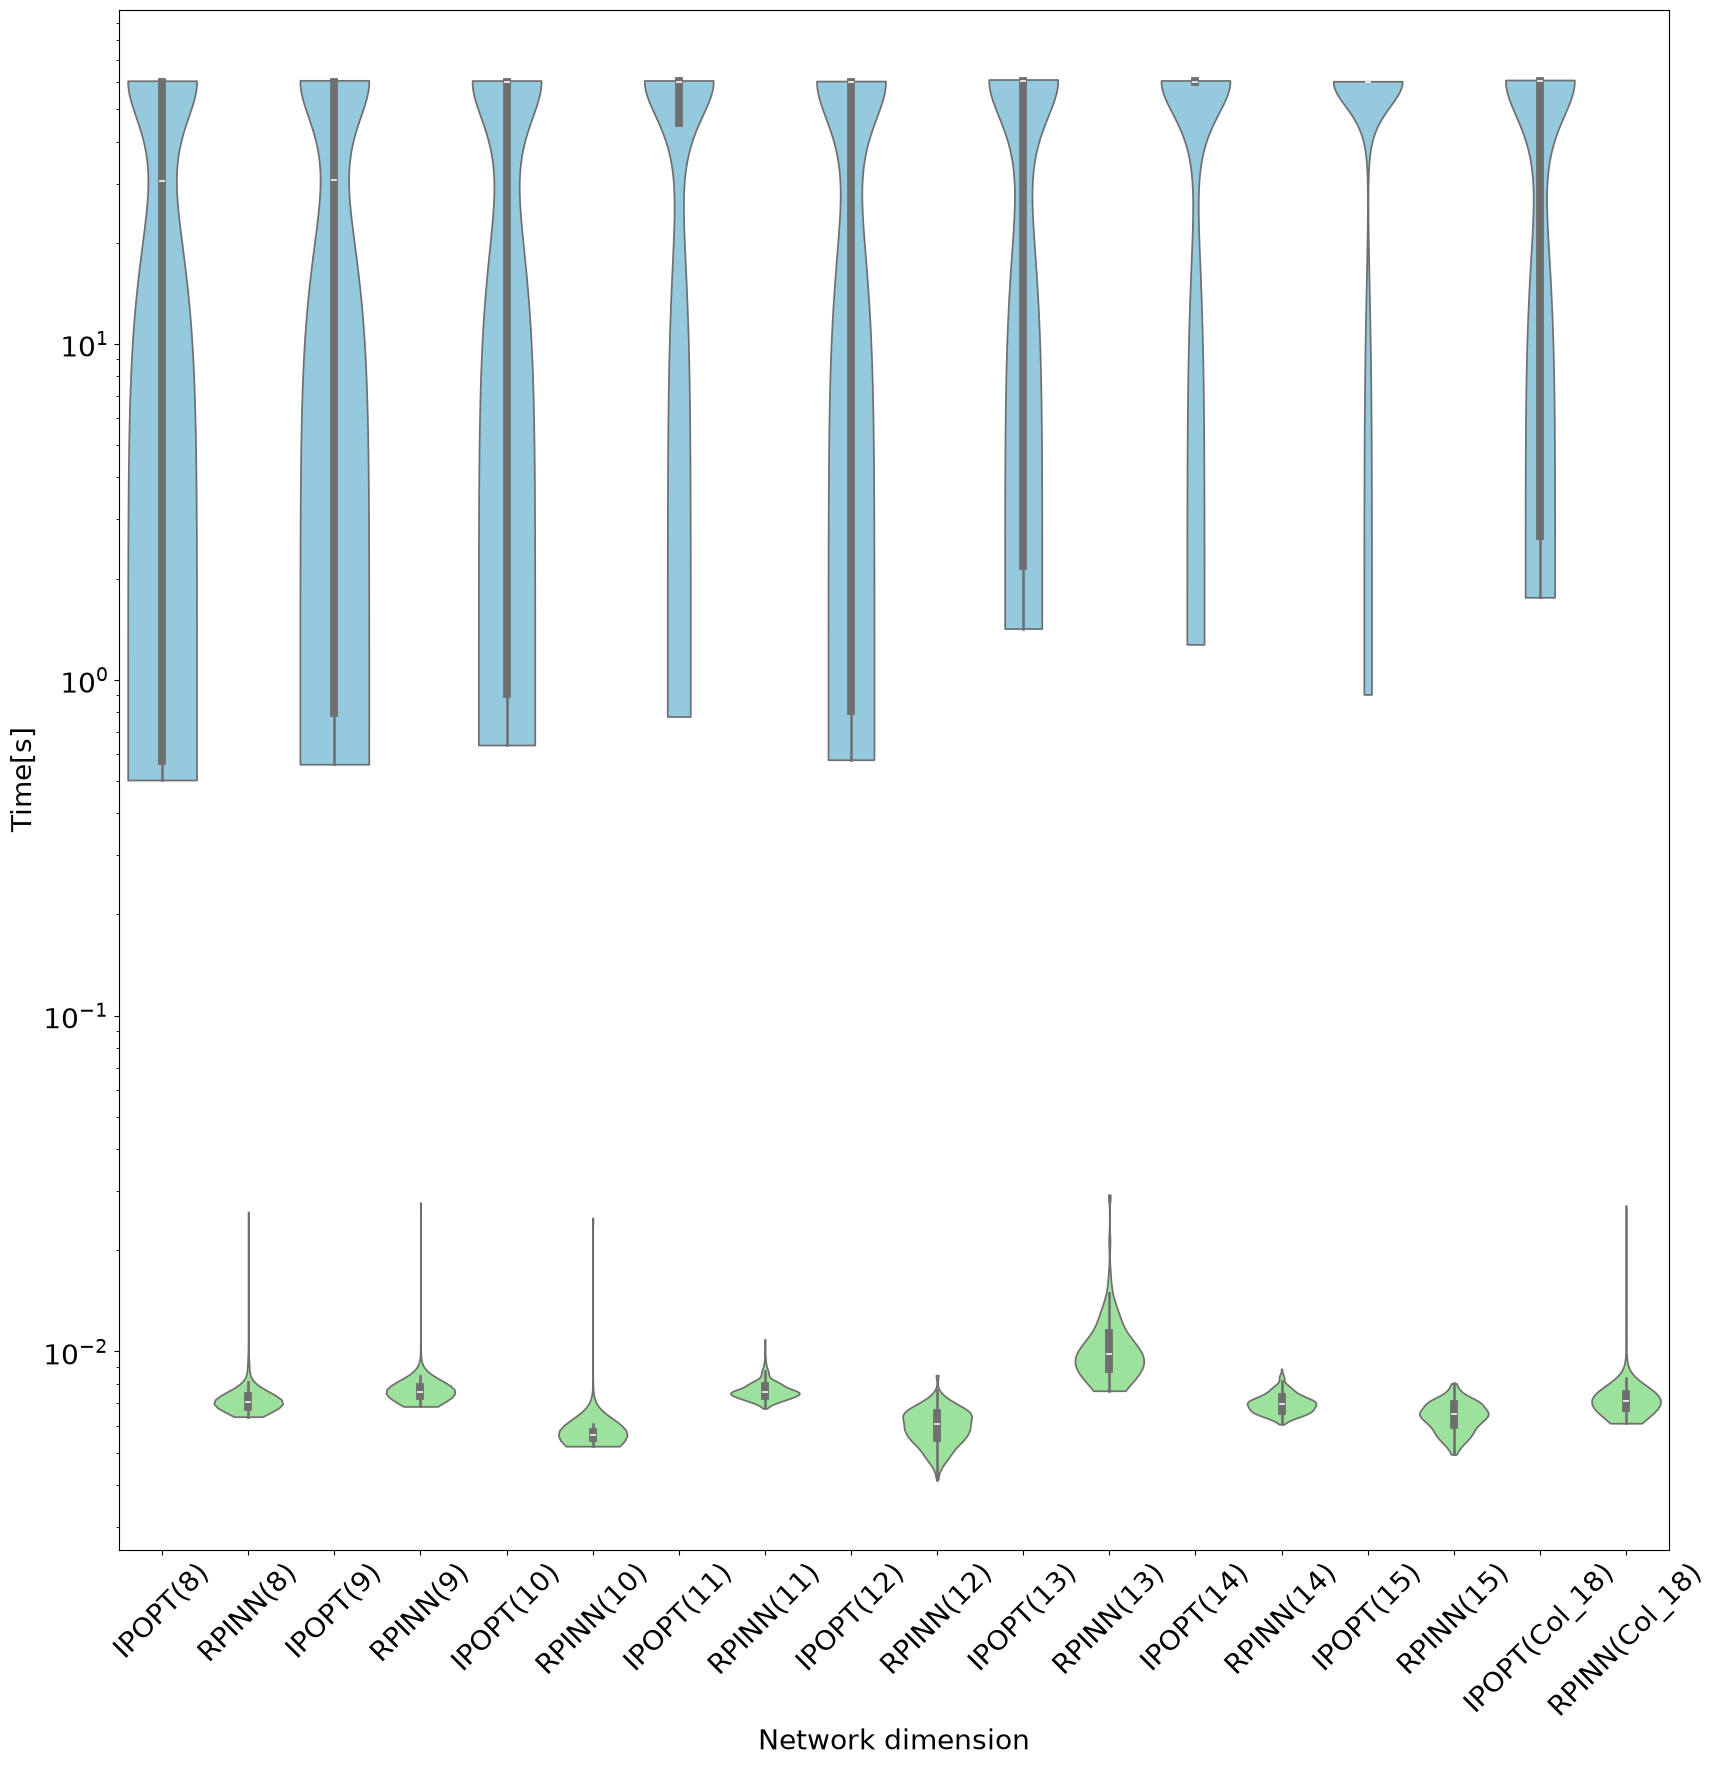

In [20]:
b=plot_time('predict',s=1)

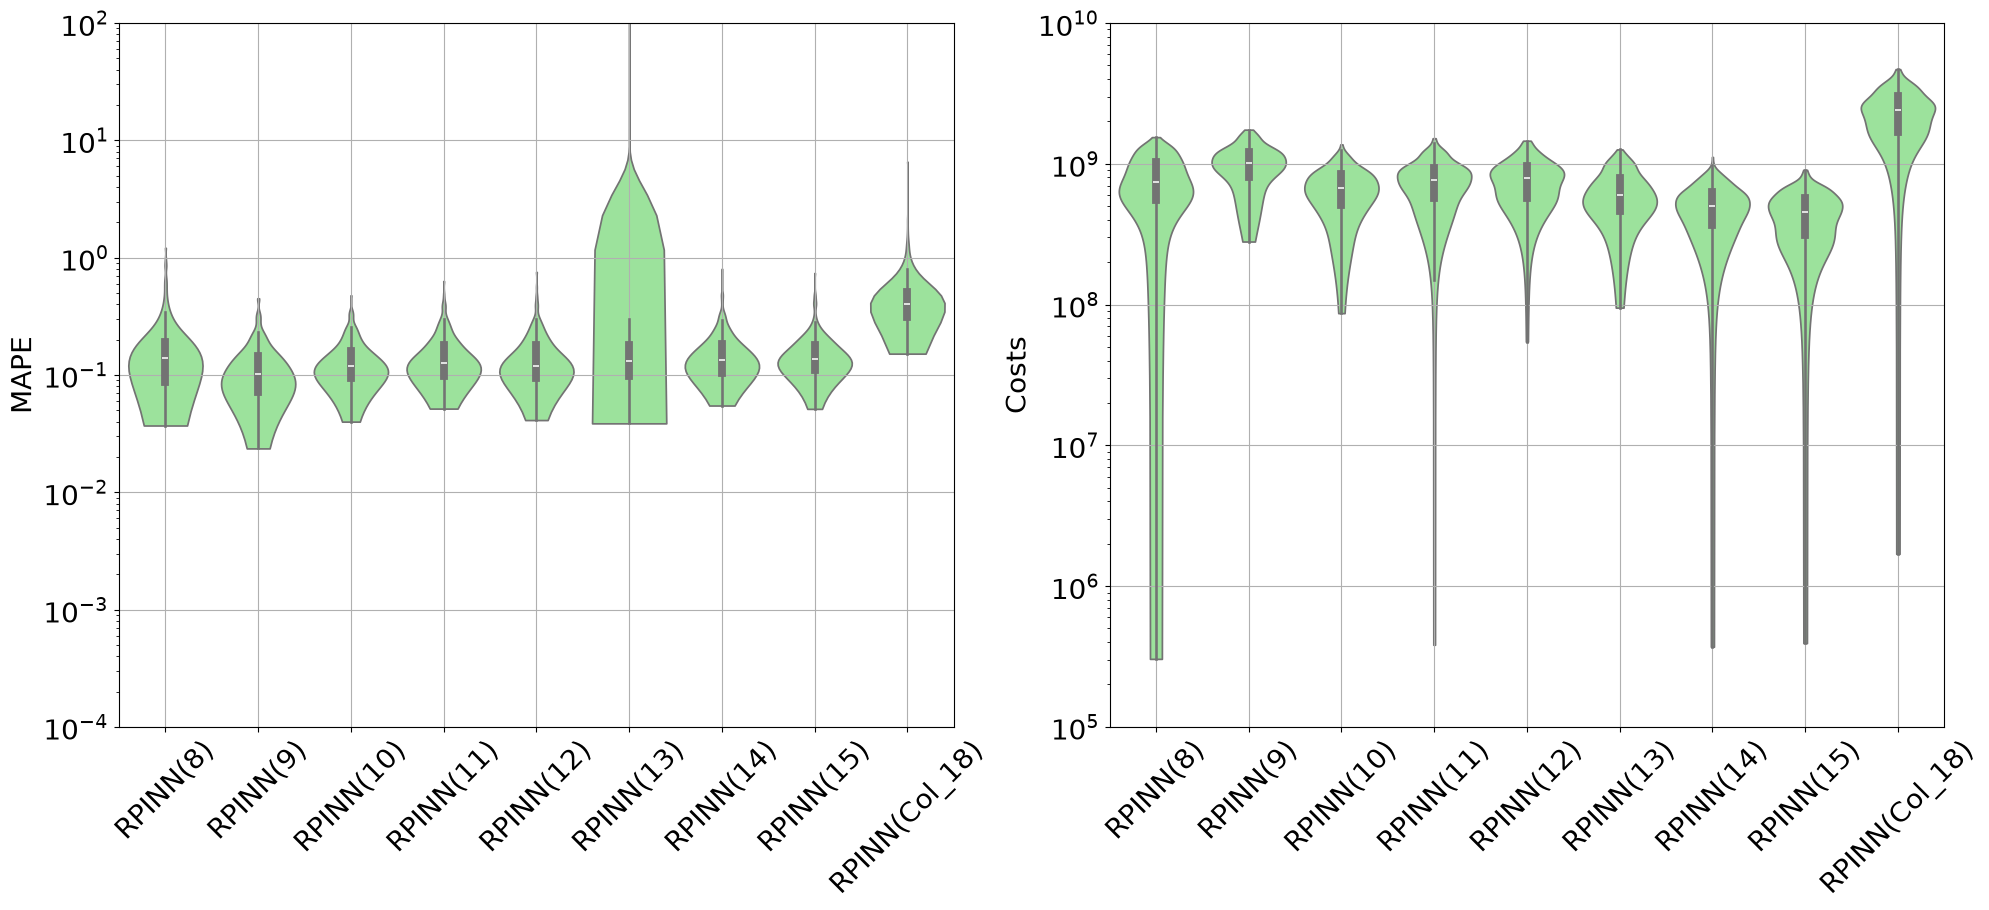

In [21]:
Bal,Wey,_,_=ng_evaluate_atip(s=1,tip1='D',tip2='MAE',selec='A')

In [22]:
# dynamic_val lives in RPINN.model_real_data_ (models of the paper campaign, seeded demand)

<Figure size 1500x500 with 0 Axes>

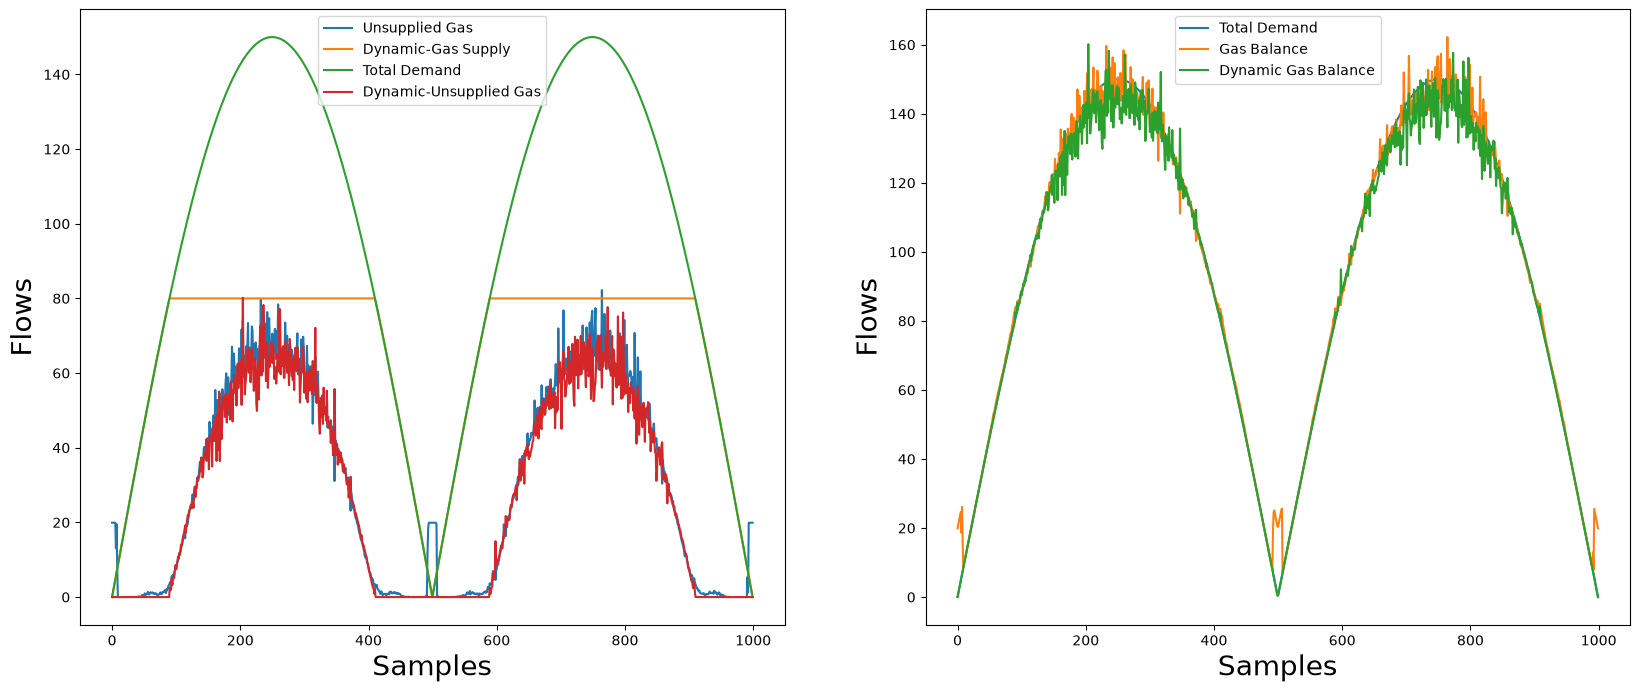

In [23]:
dynamic_val()

#Paper 2

Flows and pressures of RPINN (green) and IPOPT (blue) against their limits (stars), on the held-out samples IPOPT solved.

In [24]:
def interleave_arrays(real, predicted):
    """Interleave two arrays (real and predicted) along the second axis."""
    interleaved = np.empty((real.shape[0], real.shape[1] + predicted.shape[1]), dtype=real.dtype)
    interleaved[:, 0::2] = real
    interleaved[:, 1::2] = predicted
    return interleaved
def boundedComp(s1=None,tip='S',s=1,im=8):
    """
     Generates box plots to visualize and compare performance metric differences across various models.
     This function loads performance data of different models from the Weymouth.xlsx, Balance.xlsx, and Costos.xlsx files.
     Then, box plots are generated for each of these metrics, showing how the performance values are distributed
     among the different models.
     The plots display the Mean Absolute Percentage Error (MAPE) and costs, facilitating visual comparison between the models.
     A logarithmic scale is used to ease the visualization of data that may have a wide range of values.
     Parameters
     ----------
     s1 : str, optional
         Campaign folder (default RUN_DIR, the paper campaign).
     s : int, optional
         Determines the type of model. If 0, uses one set of models, if 1, uses another set. Default is 1
     Returns
     -------
     None
         The results are directly displayed as plots.
     """
    net = NET_IDS[im]
    path = net_path_of(net)
    Data_inf = pd.read_excel(path, sheet_name='node.info')
    Data_W = pd.read_excel(path, sheet_name='well')
    Data_T = pd.read_excel(path, sheet_name='pipe')
    Data_C = pd.read_excel(path, sheet_name='comp')
    c = campaign_case(tip, net, s, s1)
    ok = c['ok']
    Flujos, P = c['ipopt']['F'][ok], c['ipopt']['P'][ok]
    Fe, Pe = c['F'][ok], c['P'][ok]
    Ft=Flujos[:, 1:1 + len(Data_T)]
    Fte = Fe[:, 1:1 + len(Data_T)]
    Fc=Flujos[:, 1 + len(Data_T):1 + len(Data_T) + len(Data_C)]
    Fce = Fe[:, 1 + len(Data_T):1 + len(Data_T) + len(Data_C)]
    Fw = Flujos[:, 0:1]
    Fwe = Fe[:, 0:1]

    fig, axs = plt.subplots(2, 2, figsize=(19, 19))
    fontsize = 10
    rotation_angle = 45
    colors = ['skyblue' if i % 2 == 0 else 'lightgreen' for i in range(2)]
    sns.violinplot(data=interleave_arrays(Fw,Fwe), inner='box', cut=0, palette=colors, ax=axs[0,0])
    axs[0, 0].set_xticklabels([1,1])
    axs[0, 0].set_ylabel('Gas injection [MMSCFD]', fontsize=fontsize)
    axs[0, 0].set_xlabel('Injection node', fontsize=fontsize)
    axs[0, 0].plot([0,1], [Data_W['Imax'].values,Data_W['Imax'].values], 'k*', markersize=15)
    axs[0, 0].plot([0,1], [0,0], 'k*', markersize=15)

    Li = Data_T['Fg_min'].values
    Ls = Data_T['Fg_max'].values
    a=np.arange(2, 2 + len(Data_T))
    b=np.empty((a.shape[0]*2,), dtype=a.dtype)
    b[0::2] = a
    b[1::2] = a
    colors = ['skyblue' if i % 2 == 0 else 'lightgreen' for i in range(b.shape[0])]
    sns.violinplot(data=interleave_arrays(Ft,Fte), inner='box', cut=0, palette=colors, ax=axs[0,1])
    axs[0, 1].set_xticklabels(b)
    b=np.empty((Ls.shape[0]*2,), dtype=a.dtype)
    b[0::2] = Ls
    b[1::2] = Ls
    axs[0, 1].plot(np.arange(0, len(Data_T)*2), b,'k*', markersize=15)
    b=np.empty((Li.shape[0]*2,), dtype=a.dtype)
    b[0::2] = Li
    b[1::2] = Li
    axs[0, 1].plot(np.arange(0, len(Data_T)*2), b, 'k*', markersize=15)
    axs[0, 1].set_ylabel('Gas flow[MMSCFD]', fontsize=20)
    axs[0, 1].set_xlabel('Pipeline node', fontsize=20)
    axs[0, 1].tick_params(axis='x', labelsize=fontsize)
    axs[0, 1].tick_params(axis='y', labelsize=fontsize)

    Li = np.array([0] * len(Data_C))
    Ls = Data_C['fmaxc'].values

    a=np.arange(len(Data_T)+2, 2+len(Data_T) + len(Data_C))
    b=np.empty((a.shape[0]*2,), dtype=a.dtype)
    b[0::2] = a
    b[1::2] = a
    colors = ['skyblue' if i % 2 == 0 else 'lightgreen' for i in range(b.shape[0])]

    sns.violinplot(data=interleave_arrays(Fc,Fce), inner='box', cut=0, palette=colors, ax=axs[1,0])
    axs[1, 0].set_xticklabels(b)
    b=np.empty((Ls.shape[0]*2,), dtype=a.dtype)
    b[0::2] = Ls
    b[1::2] = Ls
    axs[1, 0].plot(np.arange(0, len(Data_C)*2), b,'k*', markersize=15)
    b=np.empty((Li.shape[0]*2,), dtype=a.dtype)
    b[0::2] = Li
    b[1::2] = Li
    axs[1, 0].plot(np.arange(0, len(Data_C)*2), b, 'k*', markersize=15)
    axs[1, 0].set_ylabel('Gas flow[MMSCFD]', fontsize=20)
    axs[1, 0].set_xlabel('Compressor node', fontsize=20)
    axs[1, 0].tick_params(axis='x', labelsize=fontsize)
    axs[1, 0].tick_params(axis='y', labelsize=fontsize)





    Li = Data_inf['Pmin'].values
    Ls = Data_inf['Pmax'].values
    a=np.arange(1, Pe.shape[1]+1)
    b=np.empty((a.shape[0]*2,), dtype=a.dtype)
    b[0::2] = a
    b[1::2] = a
    colors = ['skyblue' if i % 2 == 0 else 'lightgreen' for i in range(b.shape[0])]
    sns.violinplot(data=interleave_arrays(P,Pe), inner='box', cut=0, palette=colors, ax=axs[1, 1])
    axs[1, 1].set_xticklabels(b)
    b=np.empty((Ls.shape[0]*2,), dtype=a.dtype)
    b[0::2] = Ls
    b[1::2] = Ls
    axs[1, 1].plot(np.arange(0, Pe.shape[1]*2), b,'k*', markersize=15)
    b=np.empty((Li.shape[0]*2,), dtype=a.dtype)
    b[0::2] = Li
    b[1::2] = Li
    #axs[1, 1].plot(np.arange(0, Pe.shape[1]*2), b, 'k*', markersize=15)
    axs[1, 1].set_ylabel('Pressure[psia]', fontsize=20)
    axs[1, 1].set_xlabel('Pressure node', fontsize=20)
    axs[1, 1].tick_params(axis='x', labelsize=fontsize)
    #axs[1, 1].set_yscale('log')
    axs[1, 1].tick_params(axis='y', labelsize=fontsize)
    axs[1, 1].grid(True)
    axs[1, 0].grid(True)
    axs[0, 1].grid(True)
    axs[0, 0].grid(True)
    plt.savefig(f'{OUT}/LIMComp.pdf',bbox_inches='tight')
    plt.show()

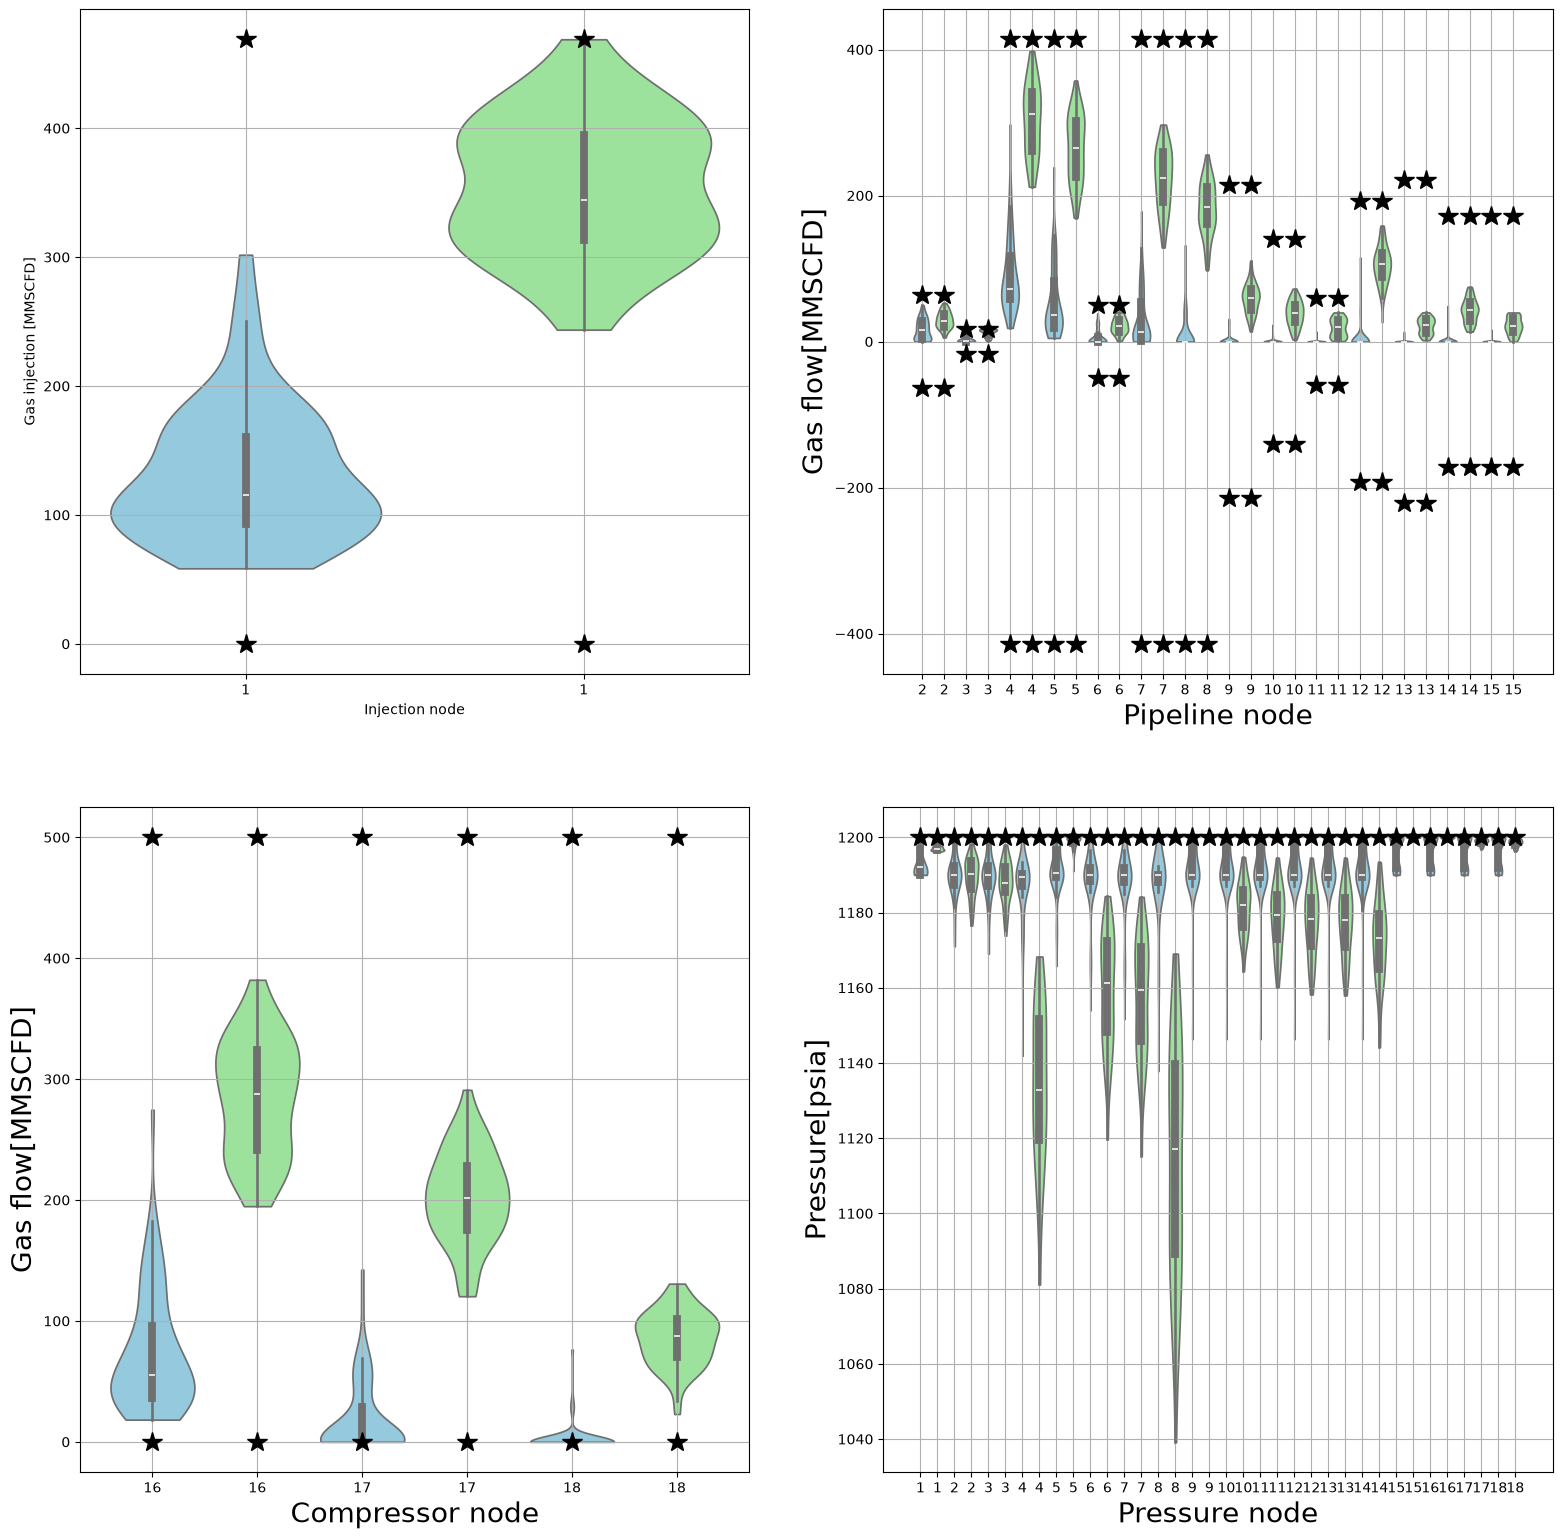

In [25]:
boundedComp(im=8)

In [26]:
def interleave_arrays(real, predicted):
    """Interleave two arrays (real and predicted) along the second axis."""
    interleaved = np.empty((real.shape[0], real.shape[1] + predicted.shape[1]), dtype=real.dtype)
    interleaved[:, 0::2] = real
    interleaved[:, 1::2] = predicted
    return interleaved
def boundedDes(s1=None,tip='S',s=1,im=8):
    """
     Generates box plots to visualize and compare performance metric differences across various models.
     This function loads performance data of different models from the Weymouth.xlsx, Balance.xlsx, and Costos.xlsx files.
     Then, box plots are generated for each of these metrics, showing how the performance values are distributed
     among the different models.
     The plots display the Mean Absolute Percentage Error (MAPE) and costs, facilitating visual comparison between the models.
     A logarithmic scale is used to ease the visualization of data that may have a wide range of values.
     Parameters
     ----------
     s1 : str, optional
         Campaign folder (default RUN_DIR, the paper campaign).
     s : int, optional
         Determines the type of model. If 0, uses one set of models, if 1, uses another set. Default is 1
     Returns
     -------
     None
         The results are directly displayed as plots.
     """
    net = NET_IDS[im]
    path = net_path_of(net)
    Data_Dc = pd.read_excel(path, sheet_name='node.demcost')
    Data_T = pd.read_excel(path, sheet_name='pipe')
    Data_C = pd.read_excel(path, sheet_name='comp')
    c = campaign_case(tip, net, s, s1)
    ok = c['ok']
    Flujos, Fe = c['ipopt']['F'][ok], c['F'][ok]
    c1=len(Data_Dc['al_Res'])
    Fd=Flujos[:, 1 + len(Data_T) + len(Data_C):1 + len(Data_T) + len(Data_C)+c1]
    Fde=Fe[:, 1 + len(Data_T) + len(Data_C):1 + len(Data_T) + len(Data_C)+c1]
    Fdm=Fd.mean(axis=1).reshape(-1,1)
    Fdem=Fde.mean(axis=1).reshape(-1,1)
    print(Fdm.shape,Fdem.shape)
    fig, axs = plt.subplots(1, 2, figsize=(10, 10))
    fontsize = 10
    rotation_angle = 45

    a=np.arange(len(Data_T)+2+len(Data_C), 2+len(Data_T) +len(Data_C)+ c1)
    b=np.empty((a.shape[0]*2,), dtype=a.dtype)
    b[0::2] = a
    b[1::2] = a
    colors = ['skyblue' if i % 2 == 0 else 'lightgreen' for i in range(b.shape[0])]
    sns.violinplot(data=interleave_arrays(Fd,Fde), inner='box', cut=0, palette=colors, ax=axs[0])
    axs[0].set_xticklabels(b)
    axs[0].set_ylabel('Gas flow[MMSCFD]', fontsize=20)
    axs[0].set_xlabel('Unsa node', fontsize=20)
    axs[0].tick_params(axis='x', labelsize=fontsize)
    axs[0].tick_params(axis='y', labelsize=fontsize)

    a=np.arange(0,1)
    b=np.empty((a.shape[0]*2,), dtype=a.dtype)
    b[0::2] = a
    b[1::2] = a
    colors = ['skyblue' if i % 2 == 0 else 'lightgreen' for i in range(b.shape[0])]
    sns.violinplot(data=interleave_arrays(Fdm,Fdem), inner='box', cut=0, palette=colors, ax=axs[1])
    axs[1].set_xticklabels(b)
    axs[1].set_ylabel('Gas flow[MMSCFD]', fontsize=20)
    axs[1].set_xlabel('Pipeline node', fontsize=20)
    axs[1].tick_params(axis='x', labelsize=fontsize)
    axs[1].tick_params(axis='y', labelsize=fontsize)


    axs[0].grid(True)
    axs[1].grid(True)
    plt.savefig(f'{OUT}/LIMDes.pdf',bbox_inches='tight')
    plt.show()

(175, 1) (175, 1)


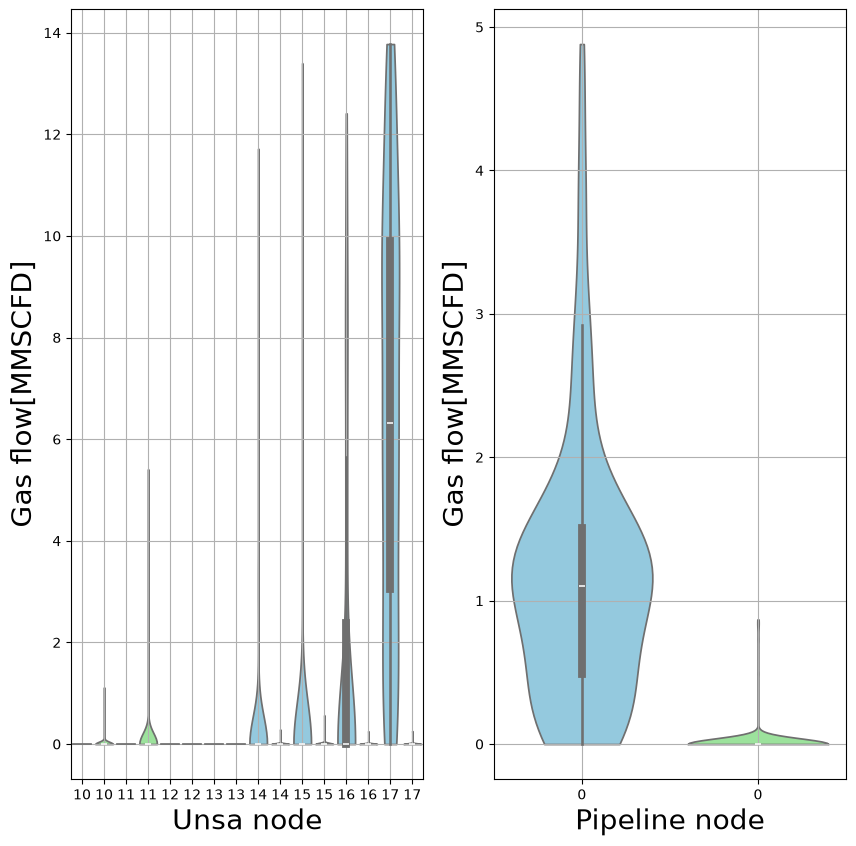

In [27]:
boundedDes(im=0)